# India — Acacia catechu: MaxEnt Python

This project adapts the supplied MaxEnt workflow for *Acacia catechu* using the occurrence workbook and India-wide WorldClim/elevation layers. The national model uses a 30-arc-second grid and a newly prepared annual Sentinel-2 NDVI layer.

Run `scripts/download_direct_seasonal.py` after authenticating Earth Engine, then run this notebook. The project reports presence-background discrimination, not occupancy accuracy; background cells are not verified absences. Write the assessed report in your own words.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from contextlib import ExitStack
from itertools import product
from importlib.metadata import version
import json, hashlib, base64, html, shutil, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio
import joblib


In [2]:
from rasterio.warp import reproject, Resampling
from rasterio.features import geometry_mask
from rasterio.transform import rowcol, xy
from rasterio.windows import Window
from shapely.geometry import mapping
from pyproj import Geod
from sklearn.cluster import KMeans
from sklearn.model_selection import GroupKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.exceptions import ConvergenceWarning
from elapid import MaxentModel


In [3]:
location = Path.cwd().resolve()
options = [location, location.parent]
ROOT = next(path for path in options if (path / "config/analysis.json").exists()
            and json.loads((path / "config/analysis.json").read_text()).get("study_area") == "India")
RAW = ROOT / "data/raw"
settings = json.loads((ROOT / "config/analysis.json").read_text())
for folder in ["data/interim", "data/processed/predictors_india", "data/raw/ndvi", "outputs/preparation"]:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(settings["seed"])


## 1. Official boundary, study grid and focal records

Read the unchanged inputs in `data/raw/` (occurrence workbook, Survey of India boundaries, India-wide 30-arc-second predictors); save all regional products under `data/interim/` and `data/processed/`. Preserve the original national context map separately. All climate/elevation layers retain their native 30-arc-second grid. Region membership, input hashes and per-cell exclusions remain traceable.


In [4]:
all_states = gpd.read_file(RAW / "boundaries/india_soi_states.gpkg").to_crs(4326)
country = gpd.read_file(RAW / "boundaries/india_soi_outline.geojson").to_crs(4326).dissolve().reset_index(drop=True)
outline = country.copy()
country.to_file(ROOT / "data/processed/india_boundary.gpkg", layer="india", driver="GPKG")
all_states.to_file(ROOT / "data/processed/india_states.gpkg", layer="states", driver="GPKG")
outline.to_file(ROOT / "data/processed/india_outline.geojson", driver="GeoJSON")
regional_bounds = country.total_bounds


In [5]:
parent_grid = json.loads((RAW / "national/india_reference_grid.json").read_text())
parent_transform = rasterio.Affine(*parent_grid["transform"])
transform = parent_transform
shape = tuple(parent_grid["shape"])
regional_window = Window(0, 0, shape[1], shape[0])
grid = {"crs": parent_grid["crs"], "shape": list(shape), "transform": parent_grid["transform"],
        "bounds": parent_grid["bounds"], "study_area": "India"}
(ROOT / "data/interim/india_reference_grid.json").write_text(json.dumps(grid, indent=2) + "\n")


322

In [6]:
inside_study = geometry_mask(country.geometry, out_shape=shape, transform=transform, invert=True)
regional_profile = dict(driver="GTiff", height=shape[0], width=shape[1], count=1, dtype="float32",
    crs=grid["crs"], transform=transform, nodata=-9999, compress="deflate", tiled=True)
raw_workbook = pd.read_excel(RAW / "occurrences/Sample Points_Species_dataset.xlsx", sheet_name="Sheet1", engine="openpyxl")
raw_workbook["source_excel_row"] = raw_workbook.index + 2
raw_workbook["species"] = raw_workbook["Species Na"].astype("string").str.strip()
raw_workbook["longitude"] = pd.to_numeric(raw_workbook["LON"], errors="coerce")
raw_workbook["latitude"] = pd.to_numeric(raw_workbook["LAT"], errors="coerce")
all_occurrences = raw_workbook.dropna(subset=["longitude", "latitude"]).copy()
all_occurrences = all_occurrences.loc[np.isfinite(all_occurrences[["longitude", "latitude"]]).all(axis=1)].copy()
all_points = gpd.GeoDataFrame(all_occurrences, geometry=gpd.points_from_xy(all_occurrences.longitude, all_occurrences.latitude), crs=4326)
focal_geo = all_points.loc[all_points.species.eq(settings["species"])].copy()
regional_points = focal_geo.loc[focal_geo.within(country.geometry.iloc[0])].copy()
other_points = all_points.loc[all_points.species.ne(settings["species"])].copy()


In [7]:
point_metric = regional_points.to_crs(7755)
regional_points["distance_to_boundary_m"] = point_metric.distance(country.to_crs(7755).boundary.iloc[0])
regional_points["near_boundary_review"] = regional_points.distance_to_boundary_m < 1000
regional_points["inside_soi_boundary"] = True
regional_points["invalid_numeric_coordinate"] = False
regional_points["outside_global_range"] = False
regional_points["exclusion_reason"] = ""
regional_points["geographic_review_status"] = np.where(regional_points.near_boundary_review,
    "inside_India_near_boundary_review", "inside_India")
regional_points.drop(columns="geometry").to_csv(ROOT / "data/interim/occurrence_geographic_review.csv", index=False)
assert len(regional_points) >= 100
pd.Series({"Acacia_catechu_records_inside_India": len(regional_points), "grid_shape": shape,
           "resolution_arcseconds": 30, "study_boundary_cells": int(inside_study.sum())}).to_frame("value")


,value
Acacia_catechu_records_inside_India,1796
grid_shape,"(3641, 3509)"
resolution_arcseconds,30
study_boundary_cells,4181737


In [8]:
focal_raw = raw_workbook.loc[raw_workbook["species"].eq(settings["species"])].copy()
focal_raw["additional_exact_coordinate_record"] = focal_raw.duplicated(["longitude", "latitude"])
region_mask = gpd.GeoSeries(gpd.points_from_xy(focal_raw.longitude, focal_raw.latitude), crs=4326).within(country.geometry.iloc[0]).to_numpy()
regional_raw = focal_raw.loc[region_mask].copy()
regional_raw.to_csv(ROOT / "data/interim/india_all_workbook_records.csv", index=False)
regional_raw.additional_exact_coordinate_record.value_counts().to_frame("records")


,records
additional_exact_coordinate_record,
False,1411
True,385


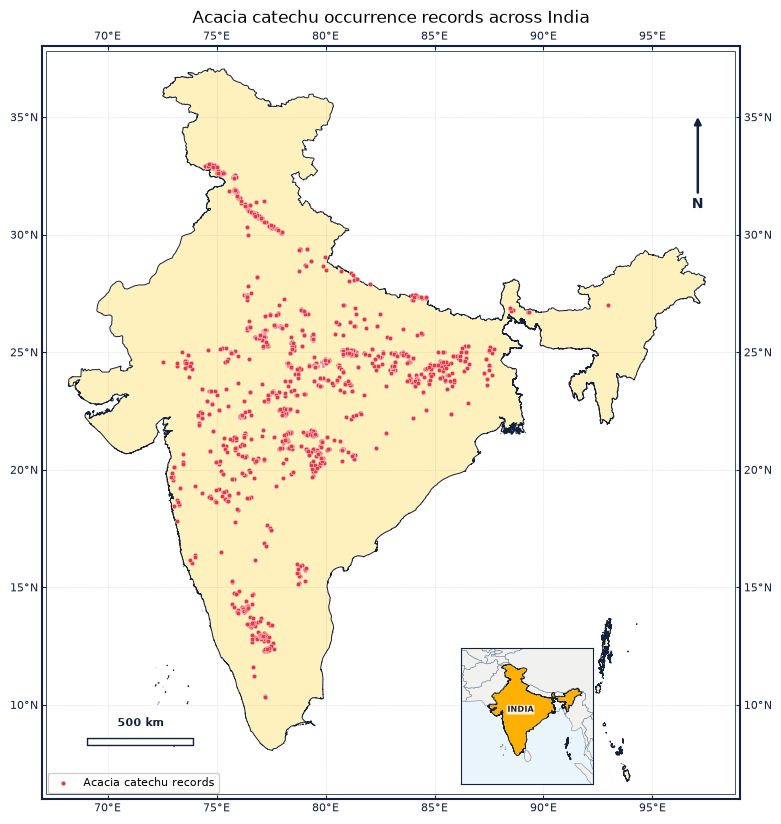

In [9]:
from matplotlib.ticker import MultipleLocator, FuncFormatter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.patches import Rectangle
from matplotlib import patheffects

# Natural Earth 1:110m country boundaries provide context for the South Asia locator.
south_asia_locator = gpd.read_file(RAW / "boundaries/south_asia_locator.geojson").to_crs(4326)


def decorate_map(ax, *, inset=True, scale=True, labelsize=8, axis_titles=False, edge_labels=True):
    """Consistent geographic furniture for maps on the India WGS84 grid."""
    geod = Geod(ellps="WGS84")
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    dx, dy = xmax - xmin, ymax - ymin
    midlat = (ymin + ymax) / 2
    ax.set_aspect(1 / np.cos(np.deg2rad(midlat)))
    lon_step = 5 if dx >= 15 else (2 if dx >= 6 else 1)
    lat_step = 5 if dy >= 15 else (2 if dy >= 6 else 1)
    ax.xaxis.set_major_locator(MultipleLocator(lon_step))
    ax.yaxis.set_major_locator(MultipleLocator(lat_step))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{abs(x):g}°{'E' if x >= 0 else 'W'}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{abs(y):g}°{'N' if y >= 0 else 'S'}"))
    ax.tick_params(labelsize=labelsize, colors="#14213d", direction="in", length=3,
        top=True, right=True, labeltop=edge_labels, labelright=edge_labels, pad=3)
    ax.grid(True, color="#52627a", alpha=0.32, linewidth=0.45, linestyle=":", zorder=4)
    if axis_titles:
        ax.set_xlabel("Longitude (WGS 84)", fontsize=labelsize + 1, color="#14213d")
        ax.set_ylabel("Latitude (WGS 84)", fontsize=labelsize + 1, color="#14213d")
    else:
        ax.set_xlabel("")
        ax.set_ylabel("")
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
        spine.set_edgecolor("#14213d")
    # Fine inner neatline echoes the double frame in the QGIS reference.
    ax.add_patch(Rectangle((0.006, 0.006), 0.988, 0.988, transform=ax.transAxes,
        fill=False, linewidth=0.55, edgecolor="#14213d", zorder=20, clip_on=False))

    # North arrow stays fixed in the frame while the map extent changes.
    ax.annotate("N", xy=(0.94, 0.91), xytext=(0.94, 0.79), xycoords="axes fraction",
        textcoords="axes fraction", ha="center", va="center", fontsize=10, fontweight="bold",
        color="#14213d", arrowprops=dict(arrowstyle="-|>", color="#14213d", lw=1.8),
        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85), zorder=10)

    if scale:
        # Compute a true east-west distance at the map's representative latitude.
        scale_km = 500 if dx >= 15 else 100
        x0 = xmin + 0.07 * dx
        y0 = ymin + 0.075 * dy
        x1, _, _ = geod.fwd(x0, y0, 90, scale_km * 1000)
        line, = ax.plot([x0, x1], [y0, y0], color="white", linewidth=4, zorder=11)
        line.set_path_effects([patheffects.Stroke(linewidth=6, foreground="#14213d"), patheffects.Normal()])
        ax.text((x0 + x1) / 2, y0 + 0.018 * dy, f"{scale_km} km", ha="center", va="bottom",
            fontsize=8, color="#14213d", fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.18", fc="white", ec="none", alpha=0.88), zorder=12)

    if inset:
        # India highlighted in the same orange used throughout the maps.
        locator = ax.inset_axes([0.60, 0.02, 0.19, 0.18])
        locator.set_facecolor("#eaf4fb")
        south_asia_locator.plot(ax=locator, facecolor="#f1f2ef", edgecolor="#64748b",
            linewidth=0.35, zorder=1)
        country.plot(ax=locator, facecolor="#ffb000", edgecolor="#14213d",
            linewidth=0.6, zorder=3)
        locator.set_xlim(60, 101)
        locator.set_ylim(-1, 42)
        locator.set_aspect("auto")
        locator.text(78.5, 22.5, "INDIA", ha="center", va="center", fontsize=5.5,
            fontweight="bold", color="#14213d",
            bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.82), zorder=5)
        locator.set_xticks([])
        locator.set_yticks([])
        locator.set_xlabel("")
        locator.set_ylabel("")
        for spine in locator.spines.values():
            spine.set_edgecolor("#14213d")
            spine.set_linewidth(0.8)

fig, ax = plt.subplots(figsize=(9, 10))
national_outline = gpd.read_file(RAW / "boundaries/india_soi_outline.geojson").to_crs(4326)
national_outline.plot(ax=ax, color="#fff1bd", edgecolor="#14213d", linewidth=0.7)
ax.scatter(regional_points.longitude, regional_points.latitude, s=11, color="#e63946",
    edgecolor="white", linewidth=0.25, label="Acacia catechu records", zorder=5)
ax.set(xlim=(67, 99), ylim=(6, 38), title="Acacia catechu occurrence records across India")
decorate_map(ax)
ax.legend(loc="lower left", fontsize=8, frameon=True, facecolor="white", framealpha=0.9)
fig.savefig(ROOT / "outputs/preparation/occurrences_india_context.png", dpi=190, bbox_inches="tight")
plt.show()


In [10]:
def clip_parent_layer(name):
    source = RAW / "predictors_india" / f"{name}.tif"
    with rasterio.open(source) as src:
        values = src.read(1, window=regional_window, masked=True).filled(-9999)
        assert src.transform.almost_equals(parent_transform)
    values[~inside_study] = -9999
    destination = ROOT / "data/processed/predictors_india" / f"{name}.tif"
    with rasterio.open(destination, "w", **regional_profile) as dst:
        dst.write(values.astype("float32"), 1)
        dst.update_tags(source=str(source.relative_to(ROOT)), study_area="India", resolution_arcseconds=30)
    return destination

clipped_layers = {name: clip_parent_layer(name) for name in [*[f"bio{i}" for i in range(1, 20)], "elevation"]}


In [11]:
inventory = pd.read_csv(RAW / "national/environmental_variables.csv")
inventory.to_csv(ROOT / "data/interim/environmental_variables.csv", index=False)
input_sources = [RAW / "occurrences/Sample Points_Species_dataset.xlsx"]
input_manifest = []
for path in input_sources:
    with path.open("rb") as handle:
        checksum = hashlib.file_digest(handle, "sha256").hexdigest()
    input_manifest.append({"file": str(path.relative_to(ROOT)), "sha256": checksum, "bytes": path.stat().st_size})
pd.DataFrame(input_manifest).to_csv(ROOT / "data/interim/input_manifest.csv", index=False)


## 2. Documented annual NDVI: direct regional download preferred

The handoff first validates the completed direct regional TIFF, its source/dates, grid and SHA-256. That file is already local. Reproduction is available via `scripts/download_direct_seasonal.py`; the normal Run All uses the cached verified file without another network computation. If the file is missing, run that script first; the notebook stops rather than substituting an undocumented NDVI.


In [94]:
import sys
sys.path.insert(0, str(ROOT / "scripts"))
from ndvi_handoff import assemble_seasonal
ndvi_handoff = assemble_seasonal(ROOT)
pd.Series(ndvi_handoff).to_frame("ndvi_handoff")


,ndvi_handoff
available,True
path,/Users/hriman/Downloads/acacia-catechu-maxent/...
coverage_percent,99.999952
processing_method,Code Editor export: per-granule NDVI evaluated...
mode,direct_tiled_grid


In [13]:
plot_xlim = (grid["bounds"][0] - 0.15, grid["bounds"][2] + 0.15)
plot_ylim = (grid["bounds"][1] - 0.15, grid["bounds"][3] + 0.15)


In [14]:
def json_value(value):
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(type(value).__name__)

packages = ["numpy", "pandas", "rasterio", "geopandas", "elapid", "scikit-learn"]
versions = {name: version(name) for name in packages}


## 3. Versioned source and modelling run

The NDVI file's SHA-256 fingerprint and the configuration hash name the run folder, so a changed input produces a separate run instead of overwriting results. All samples, tuning, evaluation, maps and HTML are rebuilt after a source change.


In [15]:
assert ndvi_handoff["available"], "Annual NDVI missing: run scripts/download_direct_seasonal.py"
ndvi_file = Path(ndvi_handoff["path"])
ndvi_files = [ndvi_file]
assert all(path.is_file() for path in ndvi_files)


In [16]:
using_annual_ndvi = ndvi_handoff["available"]
using_gee = using_annual_ndvi
using_unverified_ndvi = not using_annual_ndvi
if using_annual_ndvi:
    provenance = json.loads(ndvi_file.with_suffix(".provenance.json").read_text())
    assert (provenance.get("complete_region") or provenance.get("complete_spatial_tile_set")) and provenance["start_date"] == "2025-01-01"
    source_label, source_id = "Sentinel-2 annual mean 2025 — India", "india_gee_annual2025"
    if provenance.get("complete_region"):
        source_label, source_id = "Sentinel-2 annual mean 2025 at 30 arc-seconds", "india_gee_annual2025_directgrid"
    ndvi_period = "January–December 2025 annual mean"
    cloud_mask = provenance.get("cloud_mask") or "SCL classes 4/5/6 remapped at the requested scale (SCL is MEAN-pyramided, so averaged class codes were tested and some cloud may remain)"
else:
    raise RuntimeError("A verified seasonal India NDVI layer is required; run scripts/download_direct_seasonal.py.")


In [17]:
source_hashes = {}
for path in ndvi_files:
    with path.open("rb") as handle:
        source_hashes[str(path.relative_to(ROOT))] = hashlib.file_digest(handle, "sha256").hexdigest()
if using_annual_ndvi:
    assert source_hashes[str(ndvi_files[0].relative_to(ROOT))] == provenance["mosaic_sha256"], "Seasonal file checksum differs from its provenance."
fingerprint = hashlib.sha256(json.dumps(source_hashes, sort_keys=True).encode()).hexdigest()
settings_hash = hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()[:6]
run_id = source_id + "_" + fingerprint[:8] + "_" + settings_hash
RUN = ROOT / "outputs/runs" / run_id
for folder in ["maps", "metrics", "tables", "models", "response_curves", "report"]:
    (RUN / folder).mkdir(parents=True, exist_ok=True)
INPUTS = ROOT / "data/processed/model_runs" / run_id
INPUTS.mkdir(parents=True, exist_ok=True)
status_note = "Exploratory: occurrences confirmed WGS84" if using_gee else "Exploratory: root NDVI sensor/date/compositing unverified"
pd.Series({"run_id": run_id, "NDVI": source_label, "status": status_note}).to_frame("value")


,value
run_id,india_gee_annual2025_directgrid_a1b553fc_9dbb67
NDVI,Sentinel-2 annual mean 2025 at 30 arc-seconds
status,Exploratory: occurrences confirmed WGS84


In [18]:
def align_ndvi_file(path):
    with rasterio.open(path) as src:
        assert src.crs is not None and src.count == (2 if using_gee else 1)
        aligned = np.full((2, *shape), np.nan, dtype="float32")
        for band in range(1, src.count + 1):
            reproject(src.read(band, masked=True).filled(np.nan), aligned[band - 1],
                src_transform=src.transform, src_crs=src.crs, src_nodata=np.nan,
                dst_transform=transform, dst_crs=grid["crs"], dst_nodata=np.nan,
                resampling=Resampling.average if band == 1 else Resampling.nearest)
        if not using_gee:
            aligned[1] = np.where(np.isfinite(aligned[0]), 1, np.nan)
    return aligned


In [19]:
ndvi_sum = np.zeros(shape, dtype="float32")
ndvi_parts = np.zeros(shape, dtype="uint8")
quality = np.zeros(shape, dtype="float32")
minimum_quality = settings["minimum_gee_granules"] if using_gee else 1
for path in ndvi_files:
    aligned = align_ndvi_file(path)
    ok = np.isfinite(aligned).all(axis=0) & (aligned[0] >= -1) & (aligned[0] <= 1)
    ok &= aligned[1] >= minimum_quality
    ndvi_sum[ok] += aligned[0, ok]
    ndvi_parts[ok] += 1
    quality[ok] = np.maximum(quality[ok], aligned[1, ok])
ndvi = np.full(shape, np.nan, dtype="float32")
np.divide(ndvi_sum, ndvi_parts, out=ndvi, where=ndvi_parts > 0)
ndvi[~inside_study] = np.nan


In [20]:
profile = {"driver": "GTiff", "height": shape[0], "width": shape[1], "count": 1,
    "dtype": "float32", "crs": grid["crs"], "transform": transform,
    "nodata": -9999, "compress": "deflate", "predictor": 3, "tiled": True}
with rasterio.open(INPUTS / "ndvi.tif", "w", **profile) as dst:
    dst.write(np.where(np.isfinite(ndvi), ndvi, -9999).astype("float32"), 1)
    dst.update_tags(source=source_label, validation_status=status_note)
layer_paths = {f"bio{i}": ROOT / f"data/processed/predictors_india/bio{i}.tif" for i in range(1, 20)}
layer_paths["elevation"] = ROOT / "data/processed/predictors_india/elevation.tif"
layer_paths["ndvi"] = INPUTS / "ndvi.tif"
common = np.isfinite(ndvi)
coverage_rows = []


In [21]:
for name, path in layer_paths.items():
    with rasterio.open(path) as src:
        assert src.crs.to_epsg() == 4326 and src.shape == shape
        assert list(src.transform)[:6] == grid["transform"]
        values = src.read(1, masked=True).filled(np.nan)
    valid = np.isfinite(values)
    common &= valid
    coverage_rows.append({"variable": name, "valid_cells": int(valid.sum())})
inside_country = geometry_mask(country.geometry.map(mapping), out_shape=shape, transform=transform, invert=True)
common &= inside_country
coverage = pd.DataFrame(coverage_rows)
coverage.to_csv(RUN / "tables/predictor_coverage.csv", index=False)


In [22]:
with rasterio.open(INPUTS / "common_valid_mask.tif", "w", **profile) as dst:
    dst.write(np.where(common, 1, -9999).astype("float32"), 1)
pd.Series({"India_cells": int(inside_country.sum()), "common_valid_cells": int(common.sum()),
           "common_coverage_percent": 100 * common.sum() / inside_country.sum(),
           "reference_resolution_degrees": grid["transform"][0],
           "reference_resolution_arcseconds": 30,
           "NDVI_quality_requirement": minimum_quality,
           "quality_count_type": "granules" if using_gee else "availability only; no observation-count data"}).to_frame("value")


,value
India_cells,4181737
common_valid_cells,4176823
common_coverage_percent,99.882489
reference_resolution_degrees,0.008333
reference_resolution_arcseconds,30
NDVI_quality_requirement,3
quality_count_type,granules


In [23]:
root_ndvi_audit = {"source": source_label, "period": ndvi_period,
    "valid_India_fraction": float(np.count_nonzero(np.isfinite(ndvi) & inside_country) / inside_country.sum()),
    "common_predictor_fraction": float(common.sum() / inside_country.sum()),
    "observation_counts_available": using_gee, "status": status_note}
(ROOT / "data/interim/active_ndvi_audit.json").write_text(json.dumps(root_ndvi_audit, indent=2) + "\n")
pd.Series(root_ndvi_audit).to_frame("result")


,result
source,Sentinel-2 annual mean 2025 at 30 arc-seconds
period,January–December 2025 annual mean
valid_India_fraction,1.0
common_predictor_fraction,0.998825
observation_counts_available,True
status,Exploratory: occurrences confirmed WGS84


## 4. Traceable geographic and raster-cell cleaning

Use the existing official-SoI review; occurrence coordinates are confirmed WGS84 (EPSG:4326). Conservatively exclude outside-boundary points from this exploratory fit, preserving their near-border review flags and original row references. Keep one eligible presence per predictor cell. Exclusions and counts are outputs, not silent edits to the workbook.


In [24]:
audit = pd.read_csv(ROOT / "data/interim/occurrence_geographic_review.csv")
rows, cols = rowcol(transform, audit.longitude.to_numpy(), audit.latitude.to_numpy())
audit["grid_row"], audit["grid_col"] = rows, cols
in_bounds = (np.array(rows) >= 0) & (np.array(rows) < shape[0])
in_bounds &= (np.array(cols) >= 0) & (np.array(cols) < shape[1])
audit["complete_predictors"] = False
audit.loc[in_bounds, "complete_predictors"] = common[np.array(rows)[in_bounds], np.array(cols)[in_bounds]]
eligible = audit.inside_soi_boundary & audit.complete_predictors
audit["additional_presence_in_cell"] = False
audit.loc[eligible, "additional_presence_in_cell"] = audit.loc[eligible].duplicated(["grid_row", "grid_col"]).to_numpy()
audit["retained"] = eligible & ~audit.additional_presence_in_cell


In [25]:
audit["model_exclusion_reason"] = np.select(
    [~audit.inside_soi_boundary, ~audit.complete_predictors, audit.additional_presence_in_cell],
    ["outside_SoI_boundary", "missing_predictor_or_quality_coverage",
     "additional_record_in_reference_cell"], default="retained")
audit.to_csv(RUN / "tables/occurrence_audit.csv", index=False)
presences = audit.loc[audit.retained].copy().reset_index(drop=True)
assert len(presences) >= 100 and not presences.duplicated(["grid_row", "grid_col"]).any()
audit.model_exclusion_reason.value_counts().to_frame("records")


,records
model_exclusion_reason,
retained,1279
additional_record_in_reference_cell,516
missing_predictor_or_quality_coverage,1


## 5. Accessible region and background sampling

Primary exploratory calibration region: the union of **100 km buffers around retained records**, clipped to the official India boundary and valid predictors. This is a transparent geographic sensitivity assumption, not a claim that 100 km is the species' measured dispersal distance or historical accessible area. India remains the reporting/projection domain, not automatically the training background.

Sample 10,000 valid grid cells uniformly without replacement, excluding known occurrence cells. Uniform geographic cells do not have identical physical area. Sampling intensity and incomplete invasion equilibrium remain limitations. A later target-group sensitivity fit uses other-species survey locations as a sampling-effort proxy; those are still background, not verified absences.


In [26]:
presence_geo = gpd.GeoDataFrame(presences, geometry=gpd.points_from_xy(presences.longitude, presences.latitude), crs=4326)
metric_crs = "EPSG:7755"
presence_metric = presence_geo.to_crs(metric_crs)
accessible_geometry = presence_metric.geometry.buffer(settings["accessible_buffer_km"] * 1000).union_all()
accessible = gpd.GeoDataFrame({"buffer_km": [settings["accessible_buffer_km"]]},
    geometry=[accessible_geometry], crs=metric_crs).to_crs(4326)
accessible["geometry"] = accessible.geometry.intersection(country.geometry.iloc[0])
accessible.to_file(RUN / "tables/accessible_area.gpkg", layer="accessible", driver="GPKG")
accessible_mask = geometry_mask(accessible.geometry.map(mapping), out_shape=shape, transform=transform, invert=True)
background_mask = common & accessible_mask


In [27]:
known = audit.loc[in_bounds, ["grid_row", "grid_col"]].to_numpy(dtype=int)
background_mask[known[:, 0], known[:, 1]] = False
available = np.flatnonzero(background_mask)
assert len(available) >= settings["background_size"]
background_cells = rng.choice(available, settings["background_size"], replace=False)
bg_rows, bg_cols = np.unravel_index(background_cells, shape)
bg_x, bg_y = xy(transform, bg_rows, bg_cols)
background = pd.DataFrame({"longitude": bg_x, "latitude": bg_y, "grid_row": bg_rows, "grid_col": bg_cols})
background.to_csv(RUN / "tables/background_samples.csv", index=False)
base = pd.concat([presences.assign(presence=1), background.assign(presence=0)], ignore_index=True)
pd.Series({"retained_presences": len(presences), "background_cells": len(background),
           "available_background_cells": len(available), "accessible_buffer_km": settings["accessible_buffer_km"]}).to_frame("value")


,value
retained_presences,1279
background_cells,10000
available_background_cells,2512439
accessible_buffer_km,100


In [28]:
predictor_data = {}
for name, path in layer_paths.items():
    with rasterio.open(path) as src:
        values = src.read(1, masked=True).filled(np.nan)
    predictor_data[name] = values[base.grid_row.to_numpy(dtype=int), base.grid_col.to_numpy(dtype=int)]
X = pd.DataFrame(predictor_data)
y = base.presence.to_numpy(dtype=int)
assert np.isfinite(X.to_numpy()).all()
model_locations = gpd.GeoDataFrame(base, geometry=gpd.points_from_xy(base.longitude, base.latitude), crs=4326).to_crs(metric_crs)
coordinates_m = np.column_stack([model_locations.geometry.x, model_locations.geometry.y])
base.join(X).to_csv(RUN / "tables/presence_background_predictors.csv", index=False)


## 6. Spatial validation design fixed before model performance

Create four geographic occurrence clusters, ordered west-to-east. Reserve easternmost region 3 before inspecting regional performance. Use the other three regions for nested spatial validation, with two inner folds and a 20 km training-exclusion halo. This tests within-state transfer, not national prediction. Small and unequal regional sample counts are reported. The seven-predictor cap and regularisation search limit model complexity but do not prove adequacy. This newly defined task is not an independent replication of the national analysis, and its AUC is not directly comparable across different extents/backgrounds.


In [29]:
clusterer = KMeans(n_clusters=settings["spatial_regions"], random_state=settings["seed"], n_init=20)
clusterer.fit(coordinates_m[y == 1])
region_order = np.argsort(clusterer.cluster_centers_[:, 0])
region_labels = np.empty(settings["spatial_regions"], dtype=int)
region_labels[region_order] = np.arange(settings["spatial_regions"])
groups = region_labels[clusterer.predict(coordinates_m)]
base["spatial_region"] = groups
fold_counts = pd.crosstab(groups, y).rename(columns={0: "background", 1: "presences"})
assert fold_counts.presences.min() >= 15 and fold_counts.background.min() >= 20
fold_counts.to_csv(RUN / "tables/spatial_region_counts.csv")
fold_counts


col_0,background,presences
row_0,,
0,2119,165
1,1417,201
2,3664,582
3,2800,331


In [30]:
def buffered_training(train_ids, test_ids):
    reference = coordinates_m[test_ids][y[test_ids] == 1]
    tree = NearestNeighbors(n_neighbors=1).fit(reference)
    distance = tree.kneighbors(coordinates_m[train_ids], return_distance=True)[0].ravel()
    retained = train_ids[distance >= settings["validation_buffer_km"] * 1000]
    assert np.unique(y[retained]).size == 2 and y[retained].sum() >= 15
    return retained

holdout_ids = np.flatnonzero(groups == settings["holdout_region"])
development_ids = buffered_training(np.flatnonzero(groups != settings["holdout_region"]), holdout_ids)
assert np.intersect1d(development_ids, holdout_ids).size == 0


In [31]:
base["analysis_role"] = "buffer_excluded_from_independent_evaluation"
base.loc[development_ids, "analysis_role"] = "development"
base.loc[holdout_ids, "analysis_role"] = "reserved_geographic_holdout"
base.to_csv(RUN / "tables/spatial_assignments.csv", index=False)


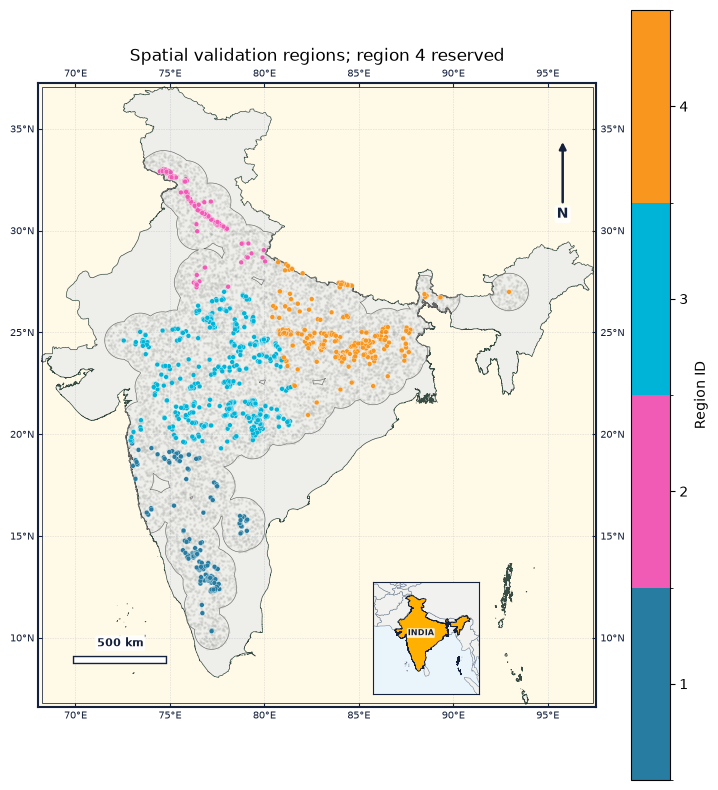

In [32]:
from matplotlib.colors import ListedColormap, BoundaryNorm
fig, ax = plt.subplots(figsize=(9, 10))
country.plot(ax=ax, color="#eeeeea", edgecolor="#384c43", linewidth=0.5, zorder=0)
accessible.boundary.plot(ax=ax, color="#666666", linewidth=0.45, zorder=1)
ax.scatter(base.loc[y == 0, "longitude"], base.loc[y == 0, "latitude"], s=1, color="#a6aaa6", alpha=0.15)
region_count = settings["spatial_regions"]
region_colors = ["#277da1", "#f15bb5", "#00b4d8", "#f8961e"][:region_count]
region_cmap = ListedColormap(region_colors)
region_norm = BoundaryNorm(np.arange(0.5, region_count + 1.5, 1), region_cmap.N)
image = ax.scatter(base.loc[y == 1, "longitude"], base.loc[y == 1, "latitude"],
    c=groups[y == 1] + 1, cmap=region_cmap, norm=region_norm, s=12, edgecolors="white", linewidths=0.2)
ax.set(xlim=plot_xlim, ylim=plot_ylim, title=f"Spatial validation regions; region {settings['holdout_region'] + 1} reserved")
fig.colorbar(image, ax=ax, label="Region ID", ticks=np.arange(1, region_count + 1))
ax.set_facecolor("#fff9e8")
ax.set(xlim=plot_xlim, ylim=plot_ylim)
decorate_map(ax, labelsize=7)
fig.savefig(RUN / "maps/spatial_regions.png", dpi=180, bbox_inches="tight")
plt.show()


## 7. Predictor selection and tuning rules

Acquire all BIO variables, but avoid fitting redundant ones blindly. A predeclared ecological priority favours vegetation, terrain, winter cold, water supply and seasonality. Within each training split, remove constants and variables with absolute Pearson correlation ≥0.8 to an already retained predictor; cap at seven (`max_predictors` in the configuration). Screening uses training background only and is repeated inside nested tuning—no holdout-based selection.

Compare linear and linear+quadratic features with four regularisation multipliers. Use a one-standard-error rule: among settings within one standard error of the best mean spatial AUC, prefer simpler features and stronger regularisation. Thresholds are reviewable choices, not universal ecological truths.


In [33]:
priority = ["ndvi", "elevation", "bio6", "bio12", "bio15", "bio4", "bio2", "bio5", "bio14", "bio3", "bio1",
            "bio13", "bio7", "bio16", "bio17", "bio10", "bio11", "bio8", "bio9", "bio18", "bio19"]

def select_predictors(train_ids):
    background_training = X.iloc[train_ids].loc[y[train_ids] == 0]
    correlations = background_training.corr().abs()
    retained = []
    for name in priority:
        if background_training[name].std() <= 1e-10:
            continue
        if not retained or correlations.loc[name, retained].max() < settings["correlation_limit"]:
            retained.append(name)
        if len(retained) == settings["max_predictors"]:
            break
    return retained


In [34]:
def fit_maxent(train_ids, candidate, columns=None):
    columns = select_predictors(train_ids) if columns is None else list(columns)
    model = MaxentModel(feature_types=list(candidate["feature_types"]),
        beta_multiplier=float(candidate["beta_multiplier"]), transform="cloglog",
        use_sklearn=True, clamp=True, class_weights=100, n_cpus=1,
        max_iter=5000, random_state=settings["seed"])
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X.iloc[train_ids][columns], y[train_ids])
    assert not any(isinstance(item.message, ConvergenceWarning) for item in caught), "Fit did not converge"
    return model, columns

candidates = [{"feature_types": feature, "beta_multiplier": beta}
              for feature, beta in product(settings["feature_candidates"], settings["beta_candidates"])]


In [35]:
def spatial_splits(ids, n_splits):
    splitter = GroupKFold(n_splits=min(n_splits, len(np.unique(groups[ids]))))
    splits = []
    for train, test in splitter.split(X.iloc[ids], y[ids], groups[ids]):
        test_ids = ids[test]
        splits.append((buffered_training(ids[train], test_ids), test_ids))
    return splits

def candidate_auc(candidate, splits):
    scores = []
    for train_ids, test_ids in splits:
        model, columns = fit_maxent(train_ids, candidate)
        scores.append(roc_auc_score(y[test_ids], model.predict(X.iloc[test_ids][columns])))
    return np.asarray(scores)


In [36]:
def tune_candidates(ids, n_splits):
    splits = spatial_splits(ids, n_splits)
    rows = []
    for candidate_id, candidate in enumerate(candidates):
        scores = candidate_auc(candidate, splits)
        rows.append({"candidate_id": candidate_id, "mean_auc": scores.mean(),
                     "sd_auc": scores.std(ddof=1), "se_auc": scores.std(ddof=1) / np.sqrt(len(scores)),
                     "feature_count": len(candidate["feature_types"]), "beta_multiplier": candidate["beta_multiplier"]})
    table = pd.DataFrame(rows)
    best = table.loc[table.mean_auc.idxmax()]
    eligible = table.loc[table.mean_auc >= best.mean_auc - best.se_auc]
    chosen = eligible.sort_values(["feature_count", "beta_multiplier", "mean_auc"], ascending=[True, False, False]).iloc[0]
    return candidates[int(chosen.candidate_id)], table


## 8. Nested spatial cross-validation and final development tuning

Outer development folds estimate the complete selection/tuning procedure. Their inner folds choose settings. The reserved region is untouched until the next section. All reported AUCs distinguish presences from sampled background, not verified absences.


In [37]:
outer_splits = spatial_splits(development_ids, len(np.unique(groups[development_ids])))
outer_results, outer_models, nested_tables = [], [], []
for fold, (train_ids, test_ids) in enumerate(outer_splits):
    chosen, table = tune_candidates(train_ids, settings["inner_folds"])
    model, columns = fit_maxent(train_ids, chosen)
    prediction = model.predict(X.iloc[test_ids][columns])
    train_prediction = model.predict(X.iloc[train_ids][columns])
    threshold = float(np.quantile(train_prediction[y[train_ids] == 1], 0.1))
    outer_results.append({"fold": fold, "train_auc": roc_auc_score(y[train_ids], train_prediction),
        "test_auc": roc_auc_score(y[test_ids], prediction), "test_omission": float((prediction[y[test_ids] == 1] < threshold).mean()),
        "test_regions": ",".join(map(str, np.unique(groups[test_ids]))),
        "test_presences": int(y[test_ids].sum()), "test_background": int((y[test_ids] == 0).sum()),
        "train_n": len(train_ids), "test_n": len(test_ids), "predictors": ", ".join(columns)})
    outer_models.append((model, columns))
    nested_tables.append(table.assign(outer_fold=fold))


In [38]:
cv_results = pd.DataFrame(outer_results)
cv_results["auc_gap"] = cv_results.train_auc - cv_results.test_auc
cv_results.to_csv(RUN / "metrics/nested_spatial_cv.csv", index=False)
pd.concat(nested_tables).to_csv(RUN / "metrics/inner_tuning.csv", index=False)
best_settings, tuning = tune_candidates(development_ids, len(np.unique(groups[development_ids])))
tuning.to_csv(RUN / "metrics/development_tuning.csv", index=False)
evaluation_model, selected = fit_maxent(development_ids, best_settings)
joblib.dump(evaluation_model, RUN / "models/evaluation_model.joblib");


In [39]:
cv_results[["fold", "train_auc", "test_auc", "auc_gap", "test_omission", "predictors"]]


,fold,train_auc,test_auc,auc_gap,test_omission,predictors
0,0,0.795639,0.725747,0.069891,0.246957,"ndvi, elevation, bio6, bio12, bio15, bio2, bio14"
1,1,0.744705,0.590233,0.154472,0.242424,"ndvi, elevation, bio6, bio12, bio15, bio4, bio2"
2,2,0.734068,0.753796,-0.019729,0.064677,"ndvi, elevation, bio6, bio12, bio15, bio2, bio5"


In [40]:
selection_correlation = X.iloc[development_ids].loc[y[development_ids] == 0].corr()
selection_table = pd.DataFrame({"variable": priority})
selection_table["retained"] = selection_table.variable.isin(selected)
selection_table["max_abs_r_to_other_retained"] = [selection_correlation.loc[name, [other for other in selected if other != name]].abs().max() for name in priority]
selection_table["decision"] = np.where(selection_table.retained, "retained by training-only priority/correlation rule", "not retained: correlation, constant or predictor cap")
selection_table.to_csv(RUN / "tables/predictor_selection.csv", index=False)
variable_table = pd.read_csv(ROOT / "data/interim/environmental_variables.csv")
variable_table["used_in_model"] = variable_table.variable.isin(selected)
variable_table["final_model_selection"] = variable_table.variable.map(selection_table.set_index("variable").decision)
variable_table.loc[variable_table.variable.eq("ndvi"), ["source", "period"]] = [source_label, ndvi_period]
variable_table.to_csv(RUN / "tables/environmental_variables.csv", index=False)
selection_table


,variable,retained,max_abs_r_to_other_retained,decision
0,ndvi,True,0.461695,retained by training-only priority/correlation...
1,elevation,True,0.590643,retained by training-only priority/correlation...
2,bio6,True,0.588832,retained by training-only priority/correlation...
3,bio12,True,0.503846,retained by training-only priority/correlation...
4,bio15,True,0.579064,retained by training-only priority/correlation...
5,bio4,False,0.815961,"not retained: correlation, constant or predict..."
6,bio2,True,0.579064,retained by training-only priority/correlation...
7,bio5,False,0.843283,"not retained: correlation, constant or predict..."
8,bio14,True,0.590643,retained by training-only priority/correlation...
9,bio3,False,0.781944,"not retained: correlation, constant or predict..."


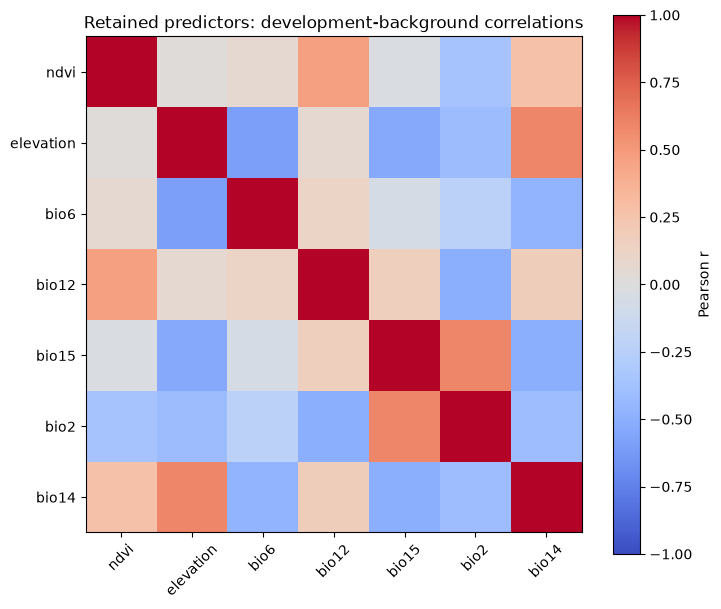

In [41]:
fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(selection_correlation.loc[selected, selected], vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(selected)), selected, rotation=45)
ax.set_yticks(range(len(selected)), selected)
ax.set_title("Retained predictors: development-background correlations")
fig.colorbar(image, ax=ax, label="Pearson r")
fig.savefig(RUN / "maps/predictor_correlations.png", dpi=160, bbox_inches="tight")
plt.show()


## 9. Reserved-region evaluation, ROC and omission diagnostics

The threshold is the 10th percentile of **development-training presence predictions**, fixed before applying it to the reserved region. Test omission is the fraction of held-out presences below that threshold. AUC ranks presences against background; background is not absence and AUC is not occupancy accuracy. The reserved region has few presences, so a stratified bootstrap (presences and background resampled separately, 2,000 replicates) gives a 95% interval for AUC and omission. It treats cells as independent and ignores spatial autocorrelation, so the true uncertainty is likely wider. A distance-only baseline checks whether geography alone can discriminate the held-out sampling pattern.


In [42]:
train_score = evaluation_model.predict(X.iloc[development_ids][selected])
test_score = evaluation_model.predict(X.iloc[holdout_ids][selected])
threshold = float(np.quantile(train_score[y[development_ids] == 1], 0.1))
train_auc = float(roc_auc_score(y[development_ids], train_score))
test_auc = float(roc_auc_score(y[holdout_ids], test_score))
test_omission = float((test_score[y[holdout_ids] == 1] < threshold).mean())
nearest = NearestNeighbors(n_neighbors=1).fit(coordinates_m[development_ids][y[development_ids] == 1])
test_distances = nearest.kneighbors(coordinates_m[holdout_ids], return_distance=True)[0].ravel()
distance_auc = float(roc_auc_score(y[holdout_ids], -test_distances))
assert test_distances[y[holdout_ids] == 1].min() >= settings["validation_buffer_km"] * 1000 - 1e-6
pd.DataFrame({"source_index": holdout_ids, "presence": y[holdout_ids], "suitability": test_score,
              "nearest_training_presence_km": test_distances / 1000}).to_csv(RUN / "tables/heldout_predictions.csv", index=False)


In [43]:
boot_rng = np.random.default_rng(settings["seed"])
test_labels = y[holdout_ids]
test_presence_rows, test_background_rows = np.flatnonzero(test_labels == 1), np.flatnonzero(test_labels == 0)
boot_auc, boot_omission = [], []
for _ in range(2000):
    sample = np.concatenate([boot_rng.choice(test_presence_rows, len(test_presence_rows)),
                             boot_rng.choice(test_background_rows, len(test_background_rows))])
    boot_auc.append(roc_auc_score(test_labels[sample], test_score[sample]))
    boot_omission.append(float((test_score[sample][test_labels[sample] == 1] < threshold).mean()))
auc_ci, omission_ci = np.quantile(boot_auc, [0.025, 0.975]), np.quantile(boot_omission, [0.025, 0.975])

In [44]:
evaluation = {"development_training_auc": train_auc, "heldout_presence_background_auc": test_auc,
    "heldout_omission_at_training_T10": test_omission,
    "heldout_auc_bootstrap_95ci": [float(auc_ci[0]), float(auc_ci[1])],
    "heldout_omission_bootstrap_95ci": [float(omission_ci[0]), float(omission_ci[1])],
    "bootstrap_replicates": len(boot_auc),
    "heldout_background_above_T10": float((test_score[y[holdout_ids] == 0] >= threshold).mean()), "training_T10_threshold": threshold,
    "distance_only_heldout_auc": distance_auc, "train_test_auc_gap": train_auc - test_auc,
    "nested_spatial_auc_mean": float(cv_results.test_auc.mean()),
    "nested_spatial_auc_sd": float(cv_results.test_auc.std(ddof=1)),
    "development_presences": int(y[development_ids].sum()), "heldout_presences": int(y[holdout_ids].sum()),
    "development_background": int((y[development_ids] == 0).sum()), "heldout_background": int((y[holdout_ids] == 0).sum()),
    "minimum_test_to_training_presence_km": float(test_distances[y[holdout_ids] == 1].min() / 1000)}
(RUN / "metrics/evaluation.json").write_text(json.dumps(evaluation, indent=2) + "\n");


In [45]:
pd.Series(evaluation).to_frame("value")


,value
development_training_auc,0.682237
heldout_presence_background_auc,0.728884
heldout_omission_at_training_T10,0.030211
heldout_auc_bootstrap_95ci,"[0.6985920371169616, 0.7580624190763918]"
heldout_omission_bootstrap_95ci,"[0.012084592145015106, 0.0513595166163142]"
bootstrap_replicates,2000
heldout_background_above_T10,0.894643
training_T10_threshold,0.343881
distance_only_heldout_auc,0.55433
train_test_auc_gap,-0.046647


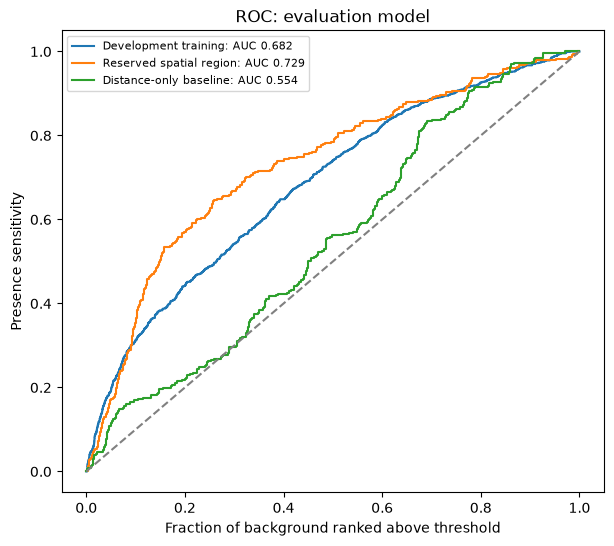

In [46]:
fig, ax = plt.subplots(figsize=(7, 6))
for labels, scores, label in [(y[development_ids], train_score, "Development training"),
                              (y[holdout_ids], test_score, "Reserved spatial region"),
                              (y[holdout_ids], -test_distances, "Distance-only baseline")]:
    fpr, tpr, _ = roc_curve(labels, scores)
    ax.plot(fpr, tpr, label=f"{label}: AUC {roc_auc_score(labels, scores):.3f}")
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set(xlabel="Fraction of background ranked above threshold", ylabel="Presence sensitivity", title="ROC: evaluation model")
ax.legend(fontsize=8)
fig.savefig(RUN / "maps/roc.png", dpi=180, bbox_inches="tight")
plt.show()


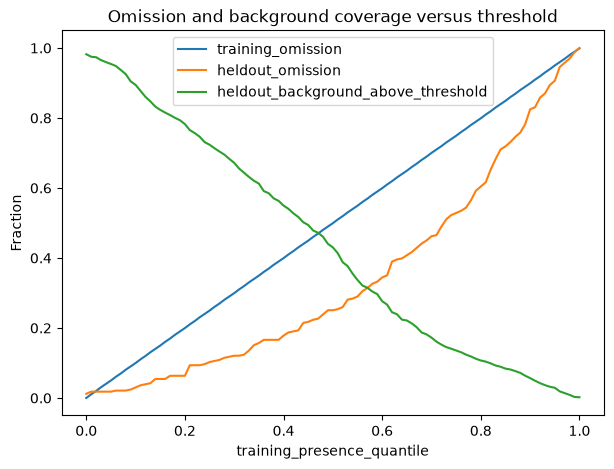

In [47]:
quantiles = np.linspace(0, 1, 101)
thresholds = np.quantile(train_score[y[development_ids] == 1], quantiles)
omission = pd.DataFrame({"training_presence_quantile": quantiles, "threshold": thresholds,
    "training_omission": [(train_score[y[development_ids] == 1] < t).mean() for t in thresholds],
    "heldout_omission": [(test_score[y[holdout_ids] == 1] < t).mean() for t in thresholds],
    "heldout_background_above_threshold": [(test_score[y[holdout_ids] == 0] >= t).mean() for t in thresholds]})
omission.to_csv(RUN / "metrics/omission_curves.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 5))
omission.plot(x="training_presence_quantile", y=["training_omission", "heldout_omission", "heldout_background_above_threshold"], ax=ax)
ax.set(ylabel="Fraction", title="Omission and background coverage versus threshold")
fig.savefig(RUN / "maps/omission.png", dpi=180, bbox_inches="tight")
plt.show()


In [48]:
learning_rows = []
for fraction in [0.25, 0.5, 0.75, 1.0]:
    pieces = [rng.choice(development_ids[y[development_ids] == label],
              max(10, int((y[development_ids] == label).sum() * fraction)), replace=False) for label in [0, 1]]
    train_ids = np.concatenate(pieces)
    model, _ = fit_maxent(train_ids, best_settings, selected)
    learning_rows.append({"training_fraction": fraction, "training_presences": int(y[train_ids].sum()),
        "training_auc": roc_auc_score(y[train_ids], model.predict(X.iloc[train_ids][selected])),
        "heldout_auc": roc_auc_score(y[holdout_ids], model.predict(X.iloc[holdout_ids][selected]))})
learning_curve = pd.DataFrame(learning_rows)
learning_curve.to_csv(RUN / "metrics/learning_curve.csv", index=False)
learning_curve


,training_fraction,training_presences,training_auc,heldout_auc
0,0.25,235,0.703111,0.714226
1,0.50,470,0.682439,0.719050
2,0.75,705,0.683787,0.727990
3,1.00,941,0.682237,0.728884


Learning-curve use of the reserved region is a post-selection diagnostic; it is not used to select settings, predictors, or a preferred NDVI source. Repeated inspection of a holdout can make later human decisions optimistic; preserve this run and declare any subsequent changes.


## 10. Required jackknife refits and held-out permutation importance

Refit the development data with only each selected variable and with that variable omitted; use the same settings and reserved evaluation samples. Bar heights are **held-out presence-background AUC**, not Java training gain. The full model is the identical reference for every refit. Correlated predictors can substitute for each other, so low leave-one-out loss does not prove ecological irrelevance. Permutation is supplementary, with ten shuffles per variable and no negative scores clipped away.


In [49]:
jackknife_rows = []
for name in selected:
    only_model, _ = fit_maxent(development_ids, best_settings, [name])
    without = [column for column in selected if column != name]
    without_model, _ = fit_maxent(development_ids, best_settings, without)
    only_auc = roc_auc_score(y[holdout_ids], only_model.predict(X.iloc[holdout_ids][[name]]))
    without_auc = roc_auc_score(y[holdout_ids], without_model.predict(X.iloc[holdout_ids][without]))
    jackknife_rows.append({"variable": name, "only_variable_auc": only_auc,
        "without_variable_auc": without_auc, "full_model_auc": test_auc, "leave_one_out_auc_loss": test_auc - without_auc})
jackknife = pd.DataFrame(jackknife_rows)
jackknife.to_csv(RUN / "metrics/jackknife.csv", index=False)


In [50]:
permutation_rows = []
for name in selected:
    losses = []
    for repeat in range(settings["permutation_repeats"]):
        shuffled = X.iloc[holdout_ids][selected].copy()
        shuffled[name] = rng.permutation(shuffled[name].to_numpy())
        losses.append(test_auc - roc_auc_score(y[holdout_ids], evaluation_model.predict(shuffled)))
    permutation_rows.append({"variable": name, "mean_auc_drop": float(np.mean(losses)),
                             "sd_auc_drop": float(np.std(losses, ddof=1)), "repeats": len(losses)})
permutation = pd.DataFrame(permutation_rows).sort_values("mean_auc_drop", ascending=False)
permutation.to_csv(RUN / "metrics/permutation_importance.csv", index=False)
permutation


,variable,mean_auc_drop,sd_auc_drop,repeats
0,ndvi,0.153773,0.012121,10
3,bio12,0.072839,0.004380,10
4,bio15,0.067479,0.006115,10
1,elevation,0.020848,0.004266,10
5,bio2,0.012148,0.006363,10
6,bio14,0.002916,0.001591,10
2,bio6,0.001374,0.002480,10


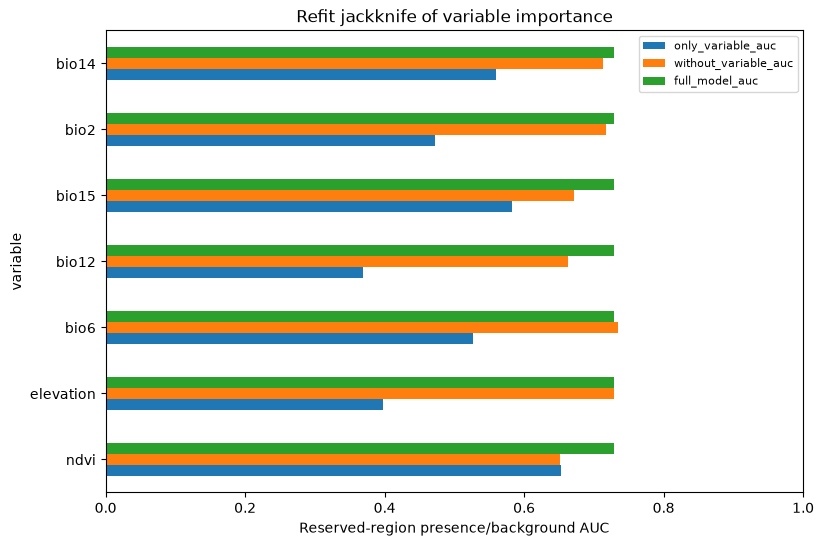

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))
jackknife.set_index("variable")[["only_variable_auc", "without_variable_auc", "full_model_auc"]].plot.barh(ax=ax)
ax.set(xlabel="Reserved-region presence/background AUC", title="Refit jackknife of variable importance", xlim=(0, 1))
ax.legend(fontsize=8)
fig.savefig(RUN / "maps/jackknife.png", dpi=180, bbox_inches="tight")
plt.show()


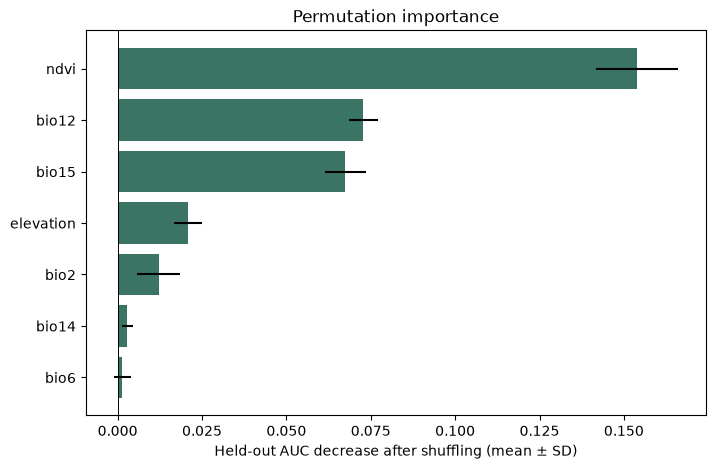

In [52]:
fig, ax = plt.subplots(figsize=(8, 5))
ordered = permutation.sort_values("mean_auc_drop")
ax.barh(ordered.variable, ordered.mean_auc_drop, xerr=ordered.sd_auc_drop, color="#397464")
ax.axvline(0, color="black", linewidth=0.7)
ax.set(xlabel="Held-out AUC decrease after shuffling (mean ± SD)", title="Permutation importance")
fig.savefig(RUN / "maps/permutation_importance.png", dpi=180, bbox_inches="tight")
plt.show()


## 11. Sampling-effort sensitivity using other-species survey locations

The same workbook supplies other-species locations as a target-group background proxy. They are not true absences and the species differ in detectability/ecology. Keep the primary model settings/predictors fixed, train the alternative only outside the reserved region and its halo, and evaluate both fits against the **same reserved presences and uniform background**. This isolates the effect of training-background choice more fairly than comparing AUCs from different test backgrounds.


In [53]:
survey = pd.read_excel(RAW / "occurrences/Sample Points_Species_dataset.xlsx", sheet_name="Sheet1",
                       usecols=["Species Na", "LON", "LAT"], engine="openpyxl")
survey["source_excel_row"] = survey.index + 2
survey = survey.loc[survey["Species Na"].astype("string").str.strip().ne(settings["species"]).fillna(False)].copy()
survey["longitude"] = pd.to_numeric(survey.LON, errors="coerce")
survey["latitude"] = pd.to_numeric(survey.LAT, errors="coerce")
survey = survey.loc[np.isfinite(survey[["longitude", "latitude"]]).all(axis=1)].copy()
tr, tc = rowcol(transform, survey.longitude.to_numpy(), survey.latitude.to_numpy())
survey["grid_row"], survey["grid_col"] = tr, tc
ok = (np.array(tr) >= 0) & (np.array(tr) < shape[0]) & (np.array(tc) >= 0) & (np.array(tc) < shape[1])
survey = survey.loc[ok].copy()
survey = survey.loc[background_mask[survey.grid_row.to_numpy(), survey.grid_col.to_numpy()]].drop_duplicates(["grid_row", "grid_col"])


In [54]:
target_background = survey.sample(min(len(survey), settings["background_size"]), random_state=settings["seed"])
assert len(target_background) >= 500
target_base = pd.concat([presences.assign(presence=1), target_background.assign(presence=0)], ignore_index=True)
target_X = {}
for name in selected:
    with rasterio.open(layer_paths[name]) as src:
        values = src.read(1, masked=True).filled(np.nan)
    target_X[name] = values[target_base.grid_row.to_numpy(dtype=int), target_base.grid_col.to_numpy(dtype=int)]
target_X = pd.DataFrame(target_X)
target_y = target_base.presence.to_numpy(dtype=int)
target_geo = gpd.GeoDataFrame(target_base, geometry=gpd.points_from_xy(target_base.longitude, target_base.latitude), crs=4326).to_crs(metric_crs)
target_coordinates = np.column_stack([target_geo.geometry.x, target_geo.geometry.y])


In [55]:
target_groups = region_labels[clusterer.predict(target_coordinates)]
heldout_tree = NearestNeighbors(n_neighbors=1).fit(coordinates_m[holdout_ids][y[holdout_ids] == 1])
target_distance = heldout_tree.kneighbors(target_coordinates, return_distance=True)[0].ravel()
target_train = (target_groups != settings["holdout_region"]) & (target_distance >= settings["validation_buffer_km"] * 1000)
target_model = MaxentModel(feature_types=list(best_settings["feature_types"]),
    beta_multiplier=best_settings["beta_multiplier"], transform="cloglog", clamp=True,
    class_weights=100, use_sklearn=True, max_iter=5000, random_state=settings["seed"], n_cpus=1)
target_model.fit(target_X.loc[target_train], target_y[target_train])
assert target_model.estimator.n_iter_.max() < 5000
target_prediction = target_model.predict(X.iloc[holdout_ids][selected])
target_threshold = float(np.quantile(target_model.predict(target_X.loc[target_train & (target_y == 1)]), 0.1))


In [56]:
background_sensitivity = pd.DataFrame([
    {"training_background": "uniform accessible cells", "shared_test_auc": test_auc,
     "shared_test_omission": test_omission, "training_background_n": int((y[development_ids] == 0).sum())},
    {"training_background": "other-species survey locations", "shared_test_auc": roc_auc_score(y[holdout_ids], target_prediction),
     "shared_test_omission": float((target_prediction[y[holdout_ids] == 1] < target_threshold).mean()),
     "training_background_n": int((target_train & (target_y == 0)).sum())}])
background_sensitivity.to_csv(RUN / "metrics/background_sensitivity.csv", index=False)
target_background.to_csv(RUN / "tables/target_group_background.csv", index=False)
joblib.dump(target_model, RUN / "models/target_group_sensitivity_model.joblib");


In [57]:
background_sensitivity


,training_background,shared_test_auc,shared_test_omission,training_background_n
0,uniform accessible cells,0.728884,0.030211,7184
1,other-species survey locations,0.431268,0.003021,4382


## 12. Spatial-thinning sensitivity

Development presences are spatially clustered, so a dense cluster can dominate the fit. Randomly thin development presences so that no two are closer than 5 km or 10 km, repeat each distance ten times, and refit with the frozen settings and predictors on the same development background. Every refit is evaluated on the same reserved presences and background. This is a sensitivity check, not a model-selection step: the primary model is unchanged whatever the result.

In [58]:
def thin_presences(ids, distance_m, generator):
    kept = []
    for index in generator.permutation(ids):
        if not kept or np.hypot(*(coordinates_m[kept] - coordinates_m[index]).T).min() >= distance_m:
            kept.append(index)
    return np.asarray(kept)

thin_rng = np.random.default_rng(settings["seed"])
development_presence_ids = development_ids[y[development_ids] == 1]
development_background_ids = development_ids[y[development_ids] == 0]
thinning_rows = [{"thinning_km": 0, "replicate": 0, "training_presences": len(development_presence_ids),
                  "heldout_auc": test_auc, "heldout_omission_T10": test_omission}]
for distance_km in [5, 10]:
    for replicate in range(10):
        kept = thin_presences(development_presence_ids, distance_km * 1000, thin_rng)
        model, _ = fit_maxent(np.concatenate([kept, development_background_ids]), best_settings, selected)
        thinned_threshold = np.quantile(model.predict(X.iloc[kept][selected]), 0.1)
        prediction = model.predict(X.iloc[holdout_ids][selected])
        thinning_rows.append({"thinning_km": distance_km, "replicate": replicate, "training_presences": len(kept),
            "heldout_auc": roc_auc_score(y[holdout_ids], prediction),
            "heldout_omission_T10": float((prediction[y[holdout_ids] == 1] < thinned_threshold).mean())})
thinning = pd.DataFrame(thinning_rows)
thinning.to_csv(RUN / "metrics/thinning_sensitivity.csv", index=False)

In [59]:
thinning_summary = thinning.groupby("thinning_km").agg(training_presences=("training_presences", "median"),
    heldout_auc_mean=("heldout_auc", "mean"), heldout_auc_min=("heldout_auc", "min"), heldout_auc_max=("heldout_auc", "max"),
    heldout_omission_mean=("heldout_omission_T10", "mean")).reset_index()
thinning_summary

,thinning_km,training_presences,heldout_auc_mean,heldout_auc_min,heldout_auc_max,heldout_omission_mean
0,0,941.0,0.728884,0.728884,0.728884,0.030211
1,5,559.5,0.721406,0.719999,0.722582,0.051360
2,10,402.0,0.720463,0.716890,0.722141,0.070695


## 13. Full-data refit and conditional response curves

After all independent evaluation, refit the frozen settings and development-selected predictors on all cleaned presence/background samples for mapping. The deployed full-data model has no separate held-out AUC of its own; earlier metrics belong to the development-trained evaluation model and nested procedure. Do not relabel a training score as an independent test score.

Response curves vary one predictor between the 1st and 99th training percentiles while holding the rest at their training medians. They show model sensitivity under that conditional scenario, not a causal effect or a guarantee that all environmental combinations occur in nature.


In [60]:
all_ids = np.arange(len(y))
final_model, _ = fit_maxent(all_ids, best_settings, selected)
joblib.dump(final_model, RUN / "models/full_data_model.joblib")
final_training_score = final_model.predict(X[selected])
final_threshold = float(np.quantile(final_training_score[y == 1], 0.1))
reference_values = X[selected].median()
response_tables = []
for name in selected:
    curve_X = pd.DataFrame([reference_values.to_dict()] * 101)
    curve_X[name] = np.linspace(X[name].quantile(0.01), X[name].quantile(0.99), 101)
    curve = pd.DataFrame({"variable": name, "value": curve_X[name], "suitability": final_model.predict(curve_X)})
    curve.to_csv(RUN / f"response_curves/{name}.csv", index=False)
    response_tables.append(curve)


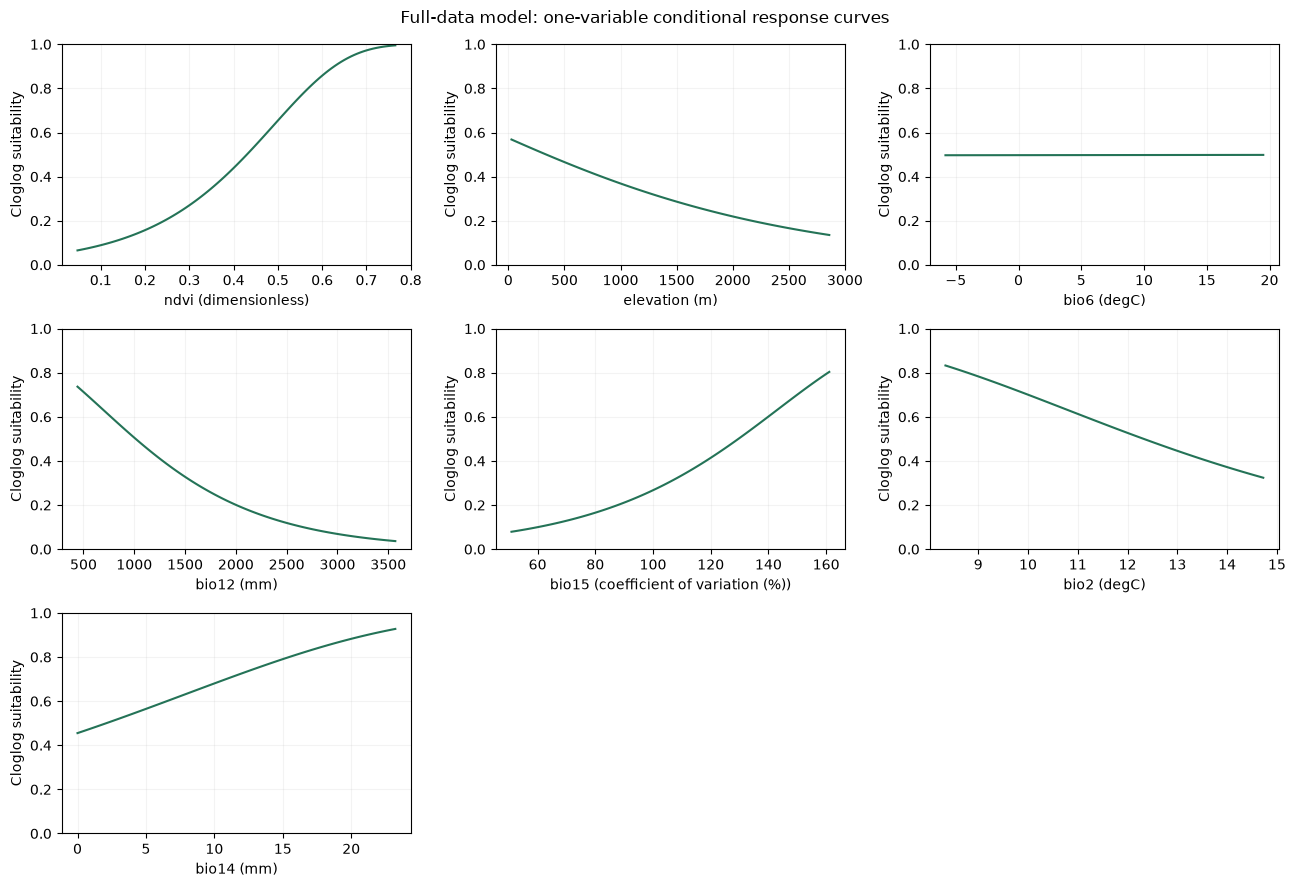

In [61]:
fig, axes = plt.subplots(int(np.ceil(len(selected) / 3)), 3, figsize=(13, 3 * int(np.ceil(len(selected) / 3))), squeeze=False)
for ax, curve in zip(axes.flat, response_tables):
    name = curve.variable.iloc[0]
    ax.plot(curve.value, curve.suitability, color="#247357")
    units = variable_table.set_index("variable").loc[name, "units"]
    ax.set(xlabel=f"{name} ({units})", ylabel="Cloglog suitability", ylim=(0, 1))
    ax.grid(alpha=0.15)
for ax in list(axes.flat)[len(selected):]:
    ax.set_visible(False)
fig.suptitle("Full-data model: one-variable conditional response curves")
fig.tight_layout()
fig.savefig(RUN / "maps/response_curves.png", dpi=170, bbox_inches="tight")
plt.show()


In [62]:
response_summary = []
for curve in response_tables:
    low, high = np.interp([curve.value.quantile(0.1), curve.value.quantile(0.9)], curve.value, curve.suitability)
    maximum = curve.loc[curve.suitability.idxmax()]
    response_summary.append({"variable": curve.variable.iloc[0], "low_to_high_change": high - low,
        "curve_peak_at": maximum.value, "peak_suitability": maximum.suitability})
response_summary = pd.DataFrame(response_summary)
response_summary.to_csv(RUN / "metrics/response_summary.csv", index=False)
response_summary


,variable,low_to_high_change,curve_peak_at,peak_suitability
0,ndvi,0.868588,0.765070,0.995146
1,elevation,-0.346688,28.000000,0.568237
2,bio6,0.001209,19.500000,0.498432
3,bio12,-0.554797,441.000000,0.736748
4,bio15,0.596354,161.078504,0.803823
5,bio2,-0.418849,8.341667,0.832782
6,bio14,0.391509,23.220000,0.927565


## 14. India projection, environmental novelty and fold disagreement

Predict window by window to avoid loading a regional 21-variable cube. Preserve the complete official boundary. Flag any cells outside the calibration region and/or beyond observed predictor ranges; clamping cannot establish ecological reliability. The standard deviation among development-fold models is a disagreement diagnostic conditional on one data source and design, not a calibrated confidence interval.


In [63]:
minimums = X[selected].min()
maximums = X[selected].max()
prediction = np.full(shape, -9999, dtype="float32")
evaluation_prediction = np.full(shape, -9999, dtype="float32")
fold_sd = np.full(shape, -9999, dtype="float32")
novelty = np.full(shape, -9999, dtype="float32")
applicability = np.full(shape, -9999, dtype="float32")
required = sorted(set(selected).union(*[set(columns) for _, columns in outer_models]))
chunk_rows = settings["prediction_chunk_rows"]


In [64]:
def predict_window(frame):
    mean = final_model.predict(frame[selected])
    folds = np.column_stack([model.predict(frame[columns]) for model, columns in outer_models])
    novel = ((frame[selected] < minimums) | (frame[selected] > maximums)).sum(axis=1).to_numpy()
    return mean, folds.std(axis=1, ddof=1), novel


In [65]:
with ExitStack() as stack:
    rasters = {name: stack.enter_context(rasterio.open(layer_paths[name])) for name in required}
    for top in range(0, shape[0], chunk_rows):
        bottom = min(top + chunk_rows, shape[0])
        valid = common[top:bottom]
        frame = pd.DataFrame({name: src.read(1, window=Window(0, top, shape[1], bottom - top))[valid]
                              for name, src in rasters.items()})
        if frame.empty:
            continue
        evaluation_prediction[top:bottom][valid] = evaluation_model.predict(frame[selected])
        mean, spread, novel = predict_window(frame)
        prediction[top:bottom][valid], fold_sd[top:bottom][valid] = mean, spread
        novelty[top:bottom][valid] = novel
        applicability[top:bottom][valid] = np.where(novel > 0, 3, np.where(accessible_mask[top:bottom][valid], 1, 2))


In [66]:
projection_layers = {"evaluation_suitability": evaluation_prediction, "habitat_suitability": prediction, "fold_model_disagreement_sd": fold_sd,
                     "environmental_novelty_count": novelty, "projection_applicability": applicability}
for name, values in projection_layers.items():
    with rasterio.open(RUN / f"maps/{name}.tif", "w", **profile) as dst:
        dst.write(values.astype("float32"), 1)
        dst.update_tags(source=source_label, model="elapid MaxEnt sklearn", validation_status=status_note)
assert np.isfinite(prediction[common]).all()
assert prediction[common].min() >= 0 and prediction[common].max() <= 1


In [67]:
def regional_plot(values, title, output, cmap="YlGnBu", vmin=None, vmax=None):
    fig, ax = plt.subplots(figsize=(9, 10))
    country.plot(ax=ax, color="#e3e5e1", edgecolor="none", zorder=0)
    masked_values = np.ma.masked_where(values == -9999, values)
    extent = [grid["bounds"][0], grid["bounds"][2], grid["bounds"][1], grid["bounds"][3]]
    if output == "projection_applicability":
        from matplotlib.colors import ListedColormap, BoundaryNorm
        from matplotlib.patches import Patch
        app_colors = ["#fff7bc", "#41b6c4", "#081d58"]
        image = ax.imshow(masked_values, cmap=ListedColormap(app_colors),
            norm=BoundaryNorm([0.5, 1.5, 2.5, 3.5], 3), extent=extent, zorder=1)
        legend_items = [
            Patch(facecolor=app_colors[0], edgecolor="#14213d", label="1  Inside M and predictor ranges"),
            Patch(facecolor=app_colors[1], edgecolor="#14213d", label="2  Outside M, in range"),
            Patch(facecolor=app_colors[2], edgecolor="#14213d", label="3  Environmental novelty")]
        ax.legend(handles=legend_items, title="Applicability class", loc="upper left",
            fontsize=7, title_fontsize=8, frameon=True, facecolor="white", framealpha=0.94)
    else:
        image = ax.imshow(masked_values, cmap=cmap, vmin=vmin, vmax=vmax,
            extent=extent, zorder=1)
        fig.colorbar(image, ax=ax, shrink=0.7)
    outline.boundary.plot(ax=ax, color="#30483c", linewidth=0.45, zorder=2)
    ax.set(xlim=plot_xlim, ylim=plot_ylim, title=title)
    decorate_map(ax)
    footer = "Boundary: Survey of India, Government of India. " + status_note
    if output == "projection_applicability":
        footer = "M = union of 100 km buffers around retained occurrences; classes describe projection support, not suitability.\n" + footer
    fig.text(0.5, 0.025, footer, ha="center", fontsize=6.5)
    fig.savefig(RUN / f"maps/{output}.png", dpi=170, bbox_inches="tight")
    plt.close(fig)

regional_plot(prediction, "Acacia catechu — India potential habitat suitability", "habitat_suitability", vmin=0, vmax=1)


In [68]:
def plot_evaluation_map():
    fig, ax = plt.subplots(figsize=(9, 10), facecolor="white")
    ax.set_facecolor("#e8edf0")
    country.plot(ax=ax, color="#e8edf0", edgecolor="none", zorder=0)
    image = ax.imshow(np.ma.masked_where(evaluation_prediction == -9999, evaluation_prediction),
        extent=[grid["bounds"][0], grid["bounds"][2], grid["bounds"][1], grid["bounds"][3]],
        cmap="YlGnBu", vmin=0, vmax=1, zorder=1)
    outline.boundary.plot(ax=ax, color="#bdbdbd", linewidth=0.35, zorder=2)
    plot_presence_roles(ax)
    ax.set(xlim=plot_xlim, ylim=plot_ylim, title=f"Acacia catechu — India evaluation model (test AUC {test_auc:.3f})")
    decorate_map(ax)
    fig.colorbar(image, ax=ax, shrink=0.65, label="Cloglog relative suitability")
    fig.text(0.5, 0.02, "Survey of India boundary; gray = missing predictor coverage; pale yellow-to-dark blue = low-to-high relative suitability. " + status_note, ha="center", fontsize=7)
    fig.savefig(RUN / "maps/evaluation_suitability_points.png", dpi=200, bbox_inches="tight")
    plt.close(fig)


In [69]:
def plot_presence_roles(ax):
    for ids, color, label in [(development_ids, "white", "Training presences"),
                              (holdout_ids, "#cf6bff", "Reserved test presences")]:
        points = base.iloc[ids].loc[lambda frame: frame.presence.eq(1)]
        ax.scatter(points.longitude, points.latitude, s=9, c=color, marker="s",
                   edgecolors="#333333", linewidths=0.15, label=f"{label} (n={len(points)})", zorder=3)
    ax.legend(loc="upper left", fontsize=8, framealpha=0.9)

plot_evaluation_map()


In [70]:
regional_plot(fold_sd, "Development-fold model disagreement (not a confidence interval)", "fold_model_disagreement_sd", vmin=0)
regional_plot(novelty, "Number of predictors outside full-training ranges", "environmental_novelty_count", cmap="magma", vmin=0)
regional_plot(applicability, "Applicability: 1 within M/ranges; 2 outside M; 3 environmental novelty", "projection_applicability", vmin=1, vmax=3)
regional_plot(np.where(common, ndvi, -9999), source_label + " — active NDVI input", "active_ndvi", cmap="YlGnBu", vmin=-1, vmax=1)


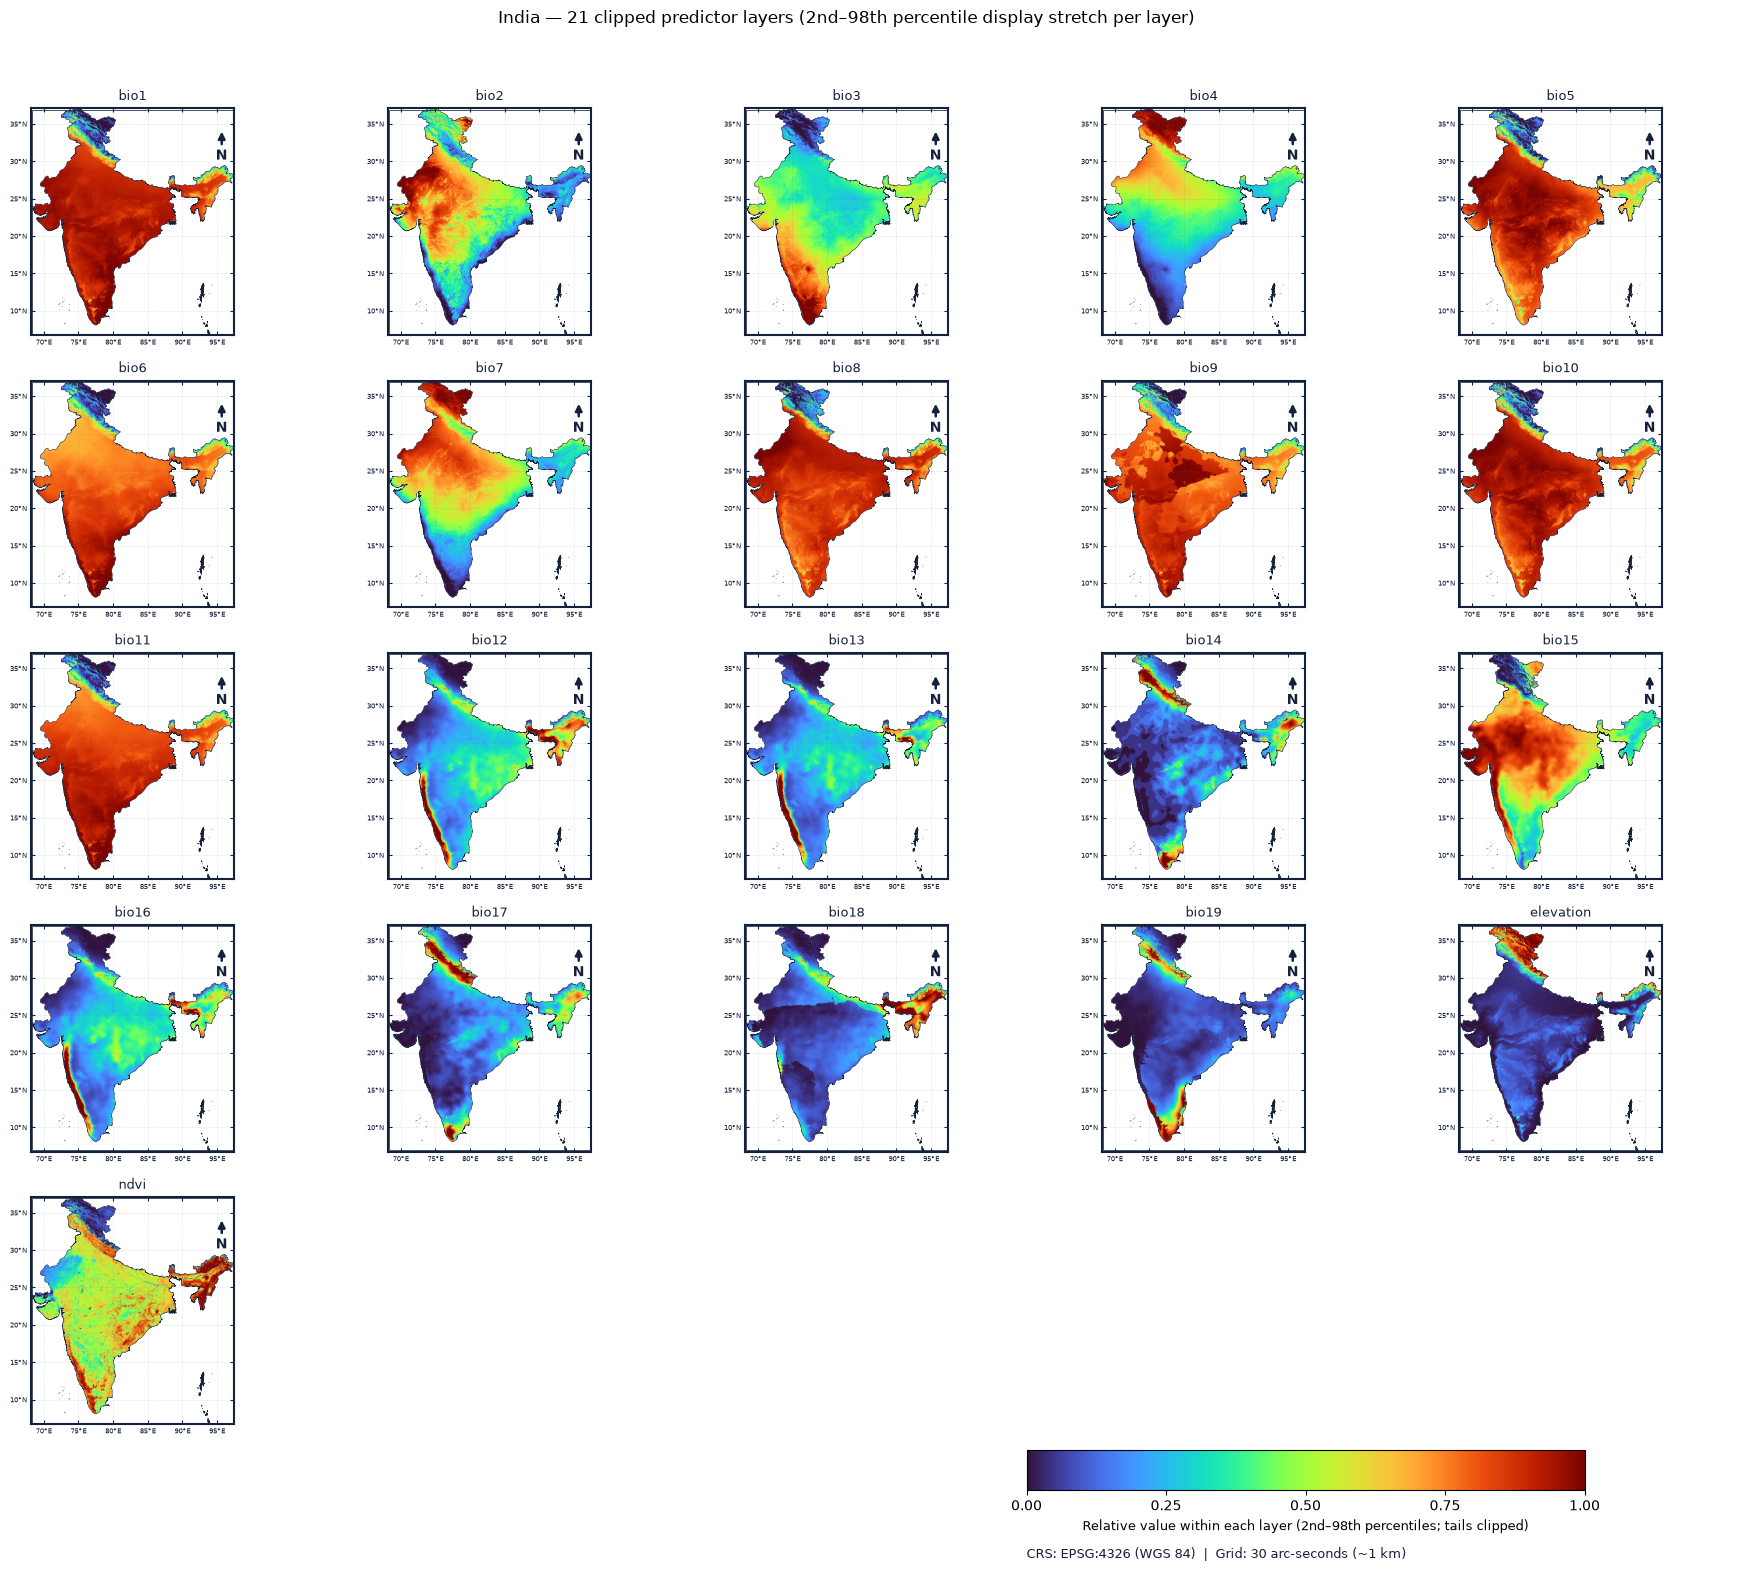

In [71]:
fig, axes = plt.subplots(5, 5, figsize=(18, 16))
layer_cmap = "turbo"
stretch_rows = []
for ax, (name, path) in zip(axes.flat, layer_paths.items()):
    with rasterio.open(path) as src:
        values = src.read(1, out_shape=(800, 800), masked=True).astype("float32")
    valid_values = values.compressed()
    lower, upper = np.percentile(valid_values, [2, 98])
    scaled = np.ma.clip((values - lower) / (upper - lower), 0, 1) if upper > lower else np.ma.zeros_like(values)
    stretch_rows.append({"variable": name, "p02_display_min": float(lower), "p98_display_max": float(upper),
        "values_below_p02_clipped": int((valid_values < lower).sum()),
        "values_above_p98_clipped": int((valid_values > upper).sum())})
    ax.imshow(scaled, extent=[grid["bounds"][0], grid["bounds"][2], grid["bounds"][1], grid["bounds"][3]],
        cmap=layer_cmap, vmin=0, vmax=1)
    country.boundary.plot(ax=ax, color="#14213d", linewidth=0.35)
    ax.set_title(name, fontsize=9, color="#14213d")
    ax.set(xlim=grid["bounds"][:1] + grid["bounds"][2:3], ylim=[grid["bounds"][1], grid["bounds"][3]])
    decorate_map(ax, inset=False, scale=False, labelsize=5, axis_titles=False, edge_labels=False)

# Keep the four unused panels blank; the shared legend and CRS use the lower margin.
for ax in axes.flat[len(layer_paths):]:
    ax.set_axis_off()
pd.DataFrame(stretch_rows).to_csv(RUN / "tables/predictor_display_stretch.csv", index=False)
fig.suptitle("India — 21 clipped predictor layers (2nd–98th percentile display stretch per layer)", y=0.99)
fig.tight_layout(rect=[0, 0.09, 1, 0.97])
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
legend_ax = fig.add_axes([0.60, 0.065, 0.31, 0.025])
shared = ScalarMappable(norm=Normalize(0, 1), cmap=layer_cmap)
bar = fig.colorbar(shared, cax=legend_ax, orientation="horizontal", ticks=[0, 0.25, 0.5, 0.75, 1])
bar.set_label("Relative value within each layer (2nd–98th percentiles; tails clipped)", fontsize=9)
fig.text(0.60, 0.025, "CRS: EPSG:4326 (WGS 84)  |  Grid: 30 arc-seconds (~1 km)",
    ha="left", va="center", fontsize=9, color="#14213d")
fig.savefig(RUN / "maps/clipped_environmental_layers.png", dpi=190, bbox_inches="tight")
plt.show()


## 15. Thresholded area summaries and regional interpretation

Compute geographic cell areas by latitude on the WGS84 ellipsoid. Report thresholded suitability only where the raster is valid, inside the exploratory accessible region and within observed predictor ranges. These are model-derived screening areas, not invaded area, population estimates or conservation priorities validated on the ground. The mapping threshold is recomputed for the full-data refit and is distinct from the held-out evaluation threshold.


In [72]:
geod = Geod(ellps="WGS84")
row_areas_km2 = []
for row in range(shape[0]):
    north_lat = transform.f + row * transform.e
    south_lat = north_lat + transform.e
    area, _ = geod.polygon_area_perimeter([grid["bounds"][0], grid["bounds"][0] + transform.a,
        grid["bounds"][0] + transform.a, grid["bounds"][0]], [north_lat, north_lat, south_lat, south_lat])
    row_areas_km2.append(abs(area) / 1e6)
row_areas_km2 = np.asarray(row_areas_km2)
supported = common & (applicability == 1)
thresholded = supported & (prediction >= final_threshold)
screening_area_km2 = float((thresholded.sum(axis=1) * row_areas_km2).sum())


In [73]:
region_statistics = []
for _, state in all_states.iterrows():
    if "DISPUTED" in state.STATE_UT or "Unassigned" in state.STATE_UT:
        continue
    state_mask = geometry_mask([mapping(state.geometry)], out_shape=shape, transform=transform, invert=True)
    valid = state_mask & supported
    area = float(((state_mask & thresholded).sum(axis=1) * row_areas_km2).sum())
    region_statistics.append({"state_ut": state.STATE_UT, "supported_cells": int(valid.sum()),
        "mean_supported_suitability": float(prediction[valid].mean()) if valid.any() else None,
        "thresholded_supported_area_km2": area,
        "predictor_coverage_fraction": float((state_mask & common).sum() / max(1, state_mask.sum()))})
state_results = pd.DataFrame(region_statistics).sort_values("thresholded_supported_area_km2", ascending=False)
state_results.to_csv(RUN / "tables/state_screening_summary.csv", index=False)
state_results.head(10)


,state_ut,supported_cells,mean_supported_suitability,thresholded_supported_area_km2,predictor_coverage_fraction
19,MADHYA PRADESH,391999,0.509491,265539.490261,1.000000
33,UTTAR PRADESH,310338,0.575969,225446.452283,1.000000
20,MAHARASHTRA,369729,0.363212,158222.772045,0.999037
28,RAJASTHAN,191862,0.622776,143641.084661,1.000000
6,CHHATTISGARH,134570,0.507652,80463.685652,1.000000
4,BIHAR,105440,0.522209,71077.901484,1.000000
15,KARNATAKA,207363,0.316882,61846.472116,0.999858
14,JHARKHAND,101777,0.485340,57269.762885,1.000000
10,GUJARAT,64884,0.673018,47369.249620,0.993910
35,WEST BENGAL,75585,0.382634,40719.244213,0.991862


## 16. Ecological reasoning grounded in measured diagnostics

These are analysis notes for review, not the assessed report prose. Link model associations to plausible processes, then discuss alternative explanations. Variable importance is conditional on the selected predictors, sampling scheme and held-out geography. A high score is not evidence of causality or confirmed invasion.


In [74]:
driver_hypotheses = {
    "ndvi": "Vegetation greenness/open-versus-closed habitat proxy; seasonal and source uncertainty constrain interpretation.",
    "elevation": "Terrain-related temperature/moisture and sampling-access proxy; not an independent physiological mechanism.",
    "bio6": "Possible cold-season constraint; interpret as a hypothesis and verify against Acacia catechu ecology literature.",
    "bio12": "Broad water availability; annual precipitation does not measure soil moisture or disturbance.",
    "bio15": "Rainfall seasonality and dry-period stress or canopy opening.",
    "bio4": "Temperature seasonality and climatic stability.",
    "bio2": "Day-night thermal variation; may proxy topography and canopy structure.",
    "bio5": "Warm-season heat exposure; coarse climate cannot resolve microsite shelter.",
    "bio14": "Driest-month water limitation; not a direct measurement of drought tolerance."}
importance_logic = permutation.merge(jackknife, on="variable").merge(response_summary, on="variable")
importance_logic["ecological_hypothesis"] = importance_logic.variable.map(driver_hypotheses).fillna("Climate association; inspect definition, covariance and ecology before mechanism claims.")
importance_logic["importance_model"] = "development-trained evaluation model"
importance_logic["response_model"] = "full-data refit"
importance_logic.to_csv(RUN / "tables/driver_interpretation_evidence.csv", index=False)


In [75]:
top_driver = permutation.iloc[0].variable
cv_mean = float(cv_results.test_auc.mean())
cv_sd = float(cv_results.test_auc.std(ddof=1))
background_auc_change = float(background_sensitivity.shared_test_auc.iloc[1] - test_auc)
projection_summary = {"final_training_T10": final_threshold,
    "screening_area_inside_M_and_ranges_km2": screening_area_km2,
    "common_coverage_percent": float(100 * common.sum() / inside_country.sum()),
    "valid_projection_cells": int(common.sum()), "environmentally_novel_cells": int(((novelty > 0) & common).sum()),
    "outside_calibration_region_cells": int((common & ~accessible_mask).sum()),
    "full_refit_training_auc_not_independent": float(roc_auc_score(y, final_training_score))}
(RUN / "metrics/projection_summary.json").write_text(json.dumps(projection_summary, indent=2) + "\n");


In [76]:
background_above = evaluation["heldout_background_above_T10"]
performance_conclusion = ("Near-chance discrimination in the reserved region; this model is not decision-ready."
    if test_auc < 0.6 else "Discrimination must be interpreted with spatial variability, bias and source caveats.")
if test_omission >= 0.3:
    performance_conclusion += f" Held-out omission is high ({100 * test_omission:.1f}% at training T10); inspect geographic transfer before any management use."
weakest_fold = cv_results.loc[cv_results.test_auc.idxmin()]
extra_logic = [
    f"Spatial transfer: the reserved-region AUC is {test_auc:.3f}; nested spatial CV averages {cv_mean:.3f} ± {cv_sd:.3f}. The weakest development fold (region {int(weakest_fold.test_regions) + 1}) scored {weakest_fold.test_auc:.3f} on {int(weakest_fold.test_presences)} presences and {int(weakest_fold.test_background)} background points.",
    f"Threshold: at the training T10 cut-off, {100 * test_omission:.1f}% of reserved presences fall below threshold, while {100 * background_above:.1f}% of reserved background points also exceed it. This broad screen should not be read as a false-positive rate; background sites are not confirmed absences.",
    f"Baseline: the distance-only model scored {distance_auc:.3f} AUC on the same reserved set, compared with {test_auc:.3f} for the environmental model. No significance test was run.",
    f"Sampling sensitivity: using other-species survey locations as training background changed reserved-set AUC by {background_auc_change:+.3f}; the alternative was not retuned.",
    f"Predictor signal: {top_driver} had the largest mean permutation-associated AUC decrease ({permutation.loc[permutation.variable.eq(top_driver), 'mean_auc_drop'].iloc[0]:.3f}). This is model-dependent association, not causal contribution.",
    "The response curves come from the full-data refit, while permutation importance and jackknife use the development-trained evaluation model; their magnitudes should not be compared directly.",
    f"Area: the thresholded projection covers {screening_area_km2:,.0f} km² inside M and observed predictor ranges. It is not an estimate of occupied or invaded area.",
    "Use: the map can help prioritize field verification. Protected-area benefits, future climate shifts and invasion risk were not evaluated."]


In [77]:
interpretation_notes = []
(RUN / "tables/interpretation_notes.json").write_text(json.dumps(interpretation_notes, indent=2) + "\n");


In [78]:
interpretation_notes = extra_logic + interpretation_notes
(RUN / "tables/interpretation_notes.json").write_text(json.dumps(interpretation_notes, indent=2) + "\n");


In [79]:
limitations = [
    "The occurrence source does not report survey dates, coordinate uncertainty or observation effort; logged exclusions can be reviewed, but unreported sampling bias remains.",
    "Keeping one presence per reference cell reduces duplicate locations, not uneven survey effort. The target-group background is a sensitivity proxy, not a complete bias correction.",
    "The 100 km calibration buffer is a working geographic assumption, not a measured dispersal distance or verified historical accessible area.",
    "WorldClim climate normals cover 1970–2000, while vegetation data represent 2025. NDVI may also reflect land use, disturbance and local plant communities.",
    "Only one geographic region was reserved for final evaluation; this is not an external validation across independent surveys or countries.",
    "Cloglog scores are relative suitability, not calibrated occupancy probabilities. Background points are not confirmed absences.",
    "Fold disagreement and permutation variation are partial diagnostics, not a complete prediction-uncertainty interval.",
    "Clamping does not validate extrapolation. Gray cells indicate missing predictor data, not unsuitable habitat.",
    "An annual NDVI mean smooths seasonal variation and does not represent species-specific phenology."]
if using_annual_ndvi:
    limitations.append("A calendar-year mean aggregates seasonal variation and does not isolate species-specific phenology; observations and phenology vary regionally.")
if using_annual_ndvi and provenance.get("complete_region"):
    limitations.append(provenance["processing_method"] + "; cloud mask: " + cloud_mask + ", evaluated at the requested scale. This is not an exact spatial mean of all 10 m NDVI pixels.")


## 17. MaxEnt Python HTML results bundle

The layout follows the familiar Java report sequence: settings/data, suitability, omission/ROC, importance, jackknife, response curves and output links. All charts/tables are computed above. The HTML embeds charts so it opens offline; linked GeoTIFFs/CSVs/models are included in the adjacent bundle. Java-specific gain and percent contribution remain explicitly unavailable, rather than being invented. Source caveats remain visible at the top.


In [80]:
run_metadata = {"run_id": run_id, "created_utc": datetime.now(timezone.utc).isoformat(),
    "implementation": "elapid.MaxentModel, sklearn L1 solver", "versions": versions,
    "settings": settings, "best_settings": best_settings, "selected_predictors": selected,
    "source_hashes": source_hashes, "source_label": source_label, "status": status_note,
    "NDVI_period": ndvi_period, "NDVI_cloud_mask": cloud_mask, "NDVI_processing": provenance.get("processing_method", "legacy native-resolution spatial means") if using_gee else "unverified root TIFF",
    "grid": grid, "evaluation": evaluation, "projection": projection_summary,
    "final_model_fit": "all cleaned data after independent evaluation; no independent test score for that refit",
    "evaluation_model_fit": "development regions only; reserved region excluded from tuning and coefficient fitting",
    "assignment_final_ready": False, "limitations": limitations}
(RUN / "models/run_metadata.json").write_text(json.dumps(run_metadata, indent=2, default=json_value) + "\n");
joblib.dump({"models": outer_models, "selected": selected}, RUN / "models/development_fold_models.joblib");


In [81]:
coefficient_rows = []
for model_name, model in [("evaluation", evaluation_model), ("full_data_refit", final_model)]:
    counters = {}
    for feature_type, coefficient in zip(model.transformer.feature_names_, model.beta_scores_):
        index = counters.get(feature_type, 0)
        counters[feature_type] = index + 1
        coefficient_rows.append({"model": model_name, "variable": selected[index],
            "feature_type": feature_type, "coefficient_transformed_scale": float(coefficient),
            "nonzero": bool(abs(coefficient) > 1e-12)})
pd.DataFrame(coefficient_rows).to_csv(RUN / "tables/feature_coefficients.csv", index=False)


In [82]:
references = [
    ("Assignment brief", "docs/assignment_brief.pdf"),
    ("Supplied Acacia catechu occurrence workbook", "data/raw/occurrences/Sample Points_Species_dataset.xlsx"),
    ("WorldClim 2.1 and SRTM-derived elevation", "https://www.worldclim.org/data/worldclim21.html"),
    ("Fick & Hijmans (2017), WorldClim 2", "https://doi.org/10.1002/joc.5086"),
    ("Survey of India boundary source", "https://surveyofindia.gov.in/pages/administrative-boundary-data-base-abdb-"),
    ("Sentinel-2 harmonized surface reflectance", "https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S2_SR_HARMONIZED"),
    ("elapid implementation", "https://earth-chris.github.io/elapid/"),
    ("Phillips, Anderson & Schapire (2006), maximum entropy modelling", "https://doi.org/10.1016/j.ecolmodel.2005.03.026"),
    ("Hijmans (2012), spatial sorting bias in SDM validation", "https://doi.org/10.1890/11-0826.1"),
    ("Roberts et al. (2017), cross-validation for spatially structured data", "https://doi.org/10.1111/ecog.02881"),
    ("Deb, D., Singh, J. P., & Chaurasia, R. S. (2015). Biomass estimation of Acacia catechu using statistical modelling. Range Management and Agroforestry, 36(2), 151–155.", "https://publications.rmsi.in/index.php/rma/article/view/341"),
    ("Fielding, A. H., & Bell, J. F. (1997). A review of methods for the assessment of prediction errors in conservation presence/absence models. Environmental Conservation, 24(1), 38–49.", "https://doi.org/10.1017/S0376892997000088"),
    ("Grubb, P. J. (1977). The maintenance of species-richness in plant communities: The importance of the regeneration niche. Biological Reviews, 52(1), 107–145.", "https://doi.org/10.1111/j.1469-185X.1977.tb01347.x"),
    ("Jha, M. N. (1995). Seed germination studies in Acacia catechu Willd. Indian Forester, 121(6), 513–517.", "https://scholar.google.com/scholar?q=%22Seed+germination+studies+in+Acacia+catechu+Willd.%22"),
    ("Jhilta, Prakriti, Rana, Neerja, Dipta, Bhawna, & Ghabru, Arti. (2018). Studies on the pod, seed and germination traits of Acacia catechu from Uttarakhand, pp. 42–46.", "https://www.zoologyjournals.com/assets/archives/2018/vol3issue4/3-4-21-681.pdf"),
    ("Negi, S. S., Tewari, J. C., & Singh, S. (1996). Natural regeneration of Acacia catechu in dry tropical forests of northern India. Journal of Tropical Forest Science, 8(4), 494–503.", "https://scholar.google.com/scholar?q=%22Natural+regeneration+of+Acacia+catechu+in+dry+tropical+forests+of+northern+India%22"),
    ("Orwa, C., Mutua, A., Kindt, R., Jamnadass, R., & Anthony, S. (2009). Acacia catechu. Agroforestree Database: A tree reference and selection guide, version 4.0.", "https://apps.worldagroforestry.org/treedb/AFTPDFS/Acacia_catechu.PDF"),
    ("Phillips, S. J. (2021). A brief tutorial on Maxent. AT&T Research.", "https://biodiversityinformatics.amnh.org/open_source/maxent/Maxent_tutorial_2021.pdf"),
    ("Puri, S., Swamy, S. L., & Jaiswal, A. K. (1994). Water relations and photosynthetic characteristics of seedlings of four dry zone tree species. Indian Journal of Forestry, 17(3), 185–192.", "https://scholar.google.com/scholar?q=%22Water+relations+and+photosynthetic+characteristics+of+seedlings+of+four+dry+zone+tree+species%22"),
    ("Singh, G., Joshi, R. D., Chopra, S. K., & Singh, A. B. (1974). Late Quaternary history of vegetation and climate of the Rajasthan desert, India. Philosophical Transactions of the Royal Society of London. Series B, Biological Sciences, 267(889), 467–501.", "https://doi.org/10.1098/rstb.1974.0013"),
    ("Raizada, A., & Juyal, G. P. (2012). Tree species diversity, species regeneration and biological productivity of seeded Acacia catechu Willd. in rehabilitated limestone mines in the North West Indian Himalayas. Land Degradation & Development, 23(2), 167–174.", "https://doi.org/10.1002/ldr.1067"),
    ("Sourabh, P., Patel, R., & Singh, V. (2023). Predicting potential habitat distribution of Acacia catechu in India. Applied Ecology and Environmental Sciences, 11(3), 99–103.", "https://doi.org/10.12691/aees-11-3-4"),
]
pd.DataFrame(references, columns=["reference", "url"]).to_csv(RUN / "tables/references.csv", index=False)


In [83]:
table_counter = 0
figure_counter = 0
COLUMN_LABELS = {
    "decision": "Screening decision", "records": "Records", "variable": "Predictor",
    "description": "Description", "units": "Units", "source": "Data source",
    "period": "Period", "used_in_model": "Retained in model", "metric": "Measure",
    "value": "Estimate", "fold": "Fold", "test_regions": "Held-out region",
    "train_auc": "Training AUC", "test_auc": "Test AUC", "test_omission": "Test omission",
    "test_presences": "Test presences", "test_background": "Test background points",
    "training_fraction": "Training-data fraction", "training_presences": "Training presences",
    "training_auc": "Training AUC", "heldout_auc": "Held-out AUC", "mean_auc_drop": "Mean AUC decrease",
    "sd_auc_drop": "SD across permutations", "repeats": "Permutations", "only_variable_auc": "Variable alone AUC",
    "without_variable_auc": "Model without variable AUC", "full_model_auc": "Full-model AUC",
    "leave_one_out_auc_loss": "AUC loss when omitted", "low_to_high_change": "Low-to-high curve change",
    "curve_peak_at": "Curve peak", "peak_suitability": "Peak model score",
    "ecological_hypothesis": "Interpretive hypothesis", "importance_model": "Importance model",
    "response_model": "Response-curve model", "training_background": "Training background",
    "shared_test_auc": "Shared-test AUC", "shared_test_omission": "Shared-test omission",
    "training_background_n": "Training background points", "thinning_km": "Minimum thinning distance (km)",
    "heldout_auc_mean": "Mean held-out AUC", "heldout_auc_min": "Minimum held-out AUC",
    "heldout_auc_max": "Maximum held-out AUC", "heldout_omission_mean": "Mean held-out omission",
    "state_ut": "State or union territory", "supported_cells": "Supported cells",
    "mean_supported_suitability": "Mean supported score", "thresholded_supported_area_km2": "Screening area (km²)",
    "predictor_coverage_fraction": "Predictor coverage", "background": "Background points",
    "presences": "Presence records", "role": "Validation role", "region": "Region",
    "auc_gap": "Training minus test AUC", "train_n": "Training sample size", "test_n": "Test sample size",
    "predictors": "Predictors"
}
TABLE_CAPTIONS = {
    "decision": "Occurrence-record screening",
    "description": "Candidate predictors, sources and selection status",
    "region": "Presence and background counts by spatial region",
    "metric": "Model evaluation metrics",
    "test_auc": "Performance across nested spatial folds",
    "training_fraction": "Learning curve",
    "ecological_hypothesis": "Predictor associations and interpretive hypotheses",
    "mean_auc_drop": "Permutation importance on the reserved region",
    "only_variable_auc": "Jackknife performance on the reserved region",
    "training_background": "Sensitivity to background sampling",
    "thinning_km": "Sensitivity to spatial thinning",
    "state_ut": "Screening estimates by state or union territory"
}

def table_html(frame, caption=None):
    global table_counter
    table_counter += 1
    display = frame.copy()
    display.columns = [COLUMN_LABELS.get(str(c), str(c).replace("_", " ").title()) for c in display.columns]
    if caption is None:
        caption = next((TABLE_CAPTIONS[k] for k in TABLE_CAPTIONS if k in set(map(str, frame.columns))), "Model results")
    table = display.to_html(index=False, border=0, classes="results", na_rep="not assessed",
                            float_format=lambda value: f"{value:,.3f}")
    table = table.replace("<thead>", f'<caption>Table {table_counter}. {html.escape(caption)}</caption><thead>', 1)
    return '<div class="table-wrap" role="region" tabindex="0" aria-label="Scrollable results table">' + table + '</div>'

def evaluation_table(metrics):
    labels = {
        "development_training_auc": "Development training AUC",
        "heldout_presence_background_auc": "Reserved-region AUC (presence vs background)",
        "heldout_omission_at_training_T10": "Reserved-region omission at training T10",
        "heldout_auc_bootstrap_95ci": "Reserved-region AUC, bootstrap 95% interval",
        "heldout_omission_bootstrap_95ci": "Omission, bootstrap 95% interval",
        "bootstrap_replicates": "Bootstrap replicates",
        "heldout_background_above_T10": "Background above training T10",
        "training_T10_threshold": "Training T10 cloglog threshold",
        "distance_only_heldout_auc": "Distance-only baseline AUC",
        "train_test_auc_gap": "Training minus reserved-region AUC",
        "nested_spatial_auc_mean": "Nested spatial CV mean AUC",
        "nested_spatial_auc_sd": "Nested spatial CV fold SD",
        "development_presences": "Development presences",
        "heldout_presences": "Reserved-region presences",
        "development_background": "Development background points",
        "heldout_background": "Reserved-region background points",
        "minimum_test_to_training_presence_km": "Minimum test-to-training presence distance"
    }
    rows = []
    count_keys = {"bootstrap_replicates", "development_presences", "heldout_presences", "development_background", "heldout_background"}
    percent_keys = {"heldout_omission_at_training_T10", "heldout_background_above_T10"}
    ci_keys = {"heldout_auc_bootstrap_95ci", "heldout_omission_bootstrap_95ci"}
    for key, value in metrics.items():
        if key in ci_keys:
            shown = f"{float(value[0]):.3f} to {float(value[1]):.3f}"
        elif key in count_keys:
            shown = f"{int(value):,}"
        elif key in percent_keys:
            shown = f"{float(value):.1%}"
        elif key == "minimum_test_to_training_presence_km":
            shown = f"{float(value):.1f} km"
        elif key == "training_T10_threshold":
            shown = f"{float(value):.3f}"
        else:
            shown = f"{float(value):.3f}"
        rows.append({"Measure": labels.get(key, key.replace("_", " ").title()), "Estimate": shown})
    return pd.DataFrame(rows)

def image_html(filename, caption):
    global figure_counter
    figure_counter += 1
    encoded = base64.b64encode((RUN / "maps" / filename).read_bytes()).decode()
    label = html.escape(caption)
    return (f'<figure class="report-figure"><a href="../maps/{html.escape(filename)}" '
            f'target="_blank" rel="noopener"><img loading="lazy" decoding="async" '
            f'src="data:image/png;base64,{encoded}" alt="{label}"></a>'
            f'<figcaption><strong>Figure {figure_counter}.</strong> {label} '
            f'<a class="full-size" href="../maps/{html.escape(filename)}" '
            f'target="_blank" rel="noopener">Open full-size figure</a></figcaption></figure>')

def section(identifier, title):
    return f'<h2 class="report-section-title" id="{identifier}">{html.escape(title)}</h2>'

parts = []


In [84]:
style = """
:root{--ink:#20252a;--muted:#58616a;--line:#cbd1d5;--green:#315642;--pale:#f5f7f8;--gold:#956317}
*{box-sizing:border-box}html{scroll-behavior:smooth;scroll-padding-top:1rem}body{margin:0 auto;max-width:1120px;padding:0 26px;background:#fff;color:var(--ink);font:15px/1.65 Arial,Helvetica,sans-serif}
a{color:#174f83;text-underline-offset:2px}a:hover{color:#0a335c}.skip-link{position:absolute;left:-9999px;top:0}.skip-link:focus{left:1rem;top:1rem;background:#fff;padding:.7rem;z-index:20}
.report-header{padding:34px 0 22px;text-align:center}.report-header h1{font:700 clamp(1.9rem,3.6vw,2.65rem)/1.16 Georgia,"Times New Roman",serif;color:#1e2933;margin:0 auto 10px;max-width:900px;letter-spacing:-.02em}.dek{font-size:1.06rem;line-height:1.5;color:#43515a;max-width:820px;margin:0 auto 14px}.report-meta{color:var(--muted);font-size:.88rem;margin:.3rem 0}.notice{background:#fafbfb;border:1px solid var(--line);border-left:4px solid var(--green);padding:14px 18px;margin:20px 0;border-radius:2px;text-align:left}.notice p{margin:.4rem 0 0}
.metric-strip{display:grid;grid-template-columns:repeat(5,minmax(0,1fr));gap:0;margin:18px 0 2px;border:1px solid var(--line)}.metric-card{padding:10px 12px;border-right:1px solid var(--line);text-align:center}.metric-card:last-child{border-right:0}.metric-card strong{display:block;color:#213b30;font-size:1.3rem;line-height:1.25;font-variant-numeric:tabular-nums}.metric-card span{display:block;color:var(--muted);font-size:.78rem;line-height:1.35;margin-top:4px}
nav{display:flex;flex-wrap:wrap;gap:3px 12px;border-top:1px solid var(--line);border-bottom:1px solid var(--line);padding:9px 4px;margin:6px 0 22px}nav a{display:inline-block;padding:3px 4px;text-decoration:none;font-size:.86rem}main{padding:0}.report-section-title{font:700 1.42rem/1.3 Arial,Helvetica,sans-serif;color:#1f2931;border-bottom:1px solid #59636b;padding:0 0 6px;margin:2.35rem 0 .9rem;scroll-margin-top:1rem}.report-section-title:first-child{margin-top:0}p{margin:.8rem 0}.small,.report-meta{color:var(--muted)}
.table-wrap{overflow-x:auto;margin:14px 0 22px;border:1px solid var(--line)}.results{border-collapse:collapse;width:100%;font-size:.86rem;line-height:1.45;font-variant-numeric:tabular-nums}.results caption{caption-side:top;text-align:left;padding:9px 10px;background:#f3f5f6;border-bottom:1px solid var(--line);font-weight:700;color:#27343c}.results th,.results td{border:1px solid #d8dde0;padding:7px 9px;text-align:left;vertical-align:top}.results th{background:#f0f2f3;color:#202a31;font-weight:700;white-space:nowrap}.results tbody tr:nth-child(even){background:#fafbfb}.results td{overflow-wrap:anywhere}
.report-figure{margin:20px auto 30px;padding:8px 0 12px;text-align:center;border-bottom:1px solid #e1e4e6}.report-figure img{display:block;width:auto;height:auto;max-width:100%;max-height:min(76vh,900px);object-fit:contain;margin:0 auto;border:1px solid #34424b;background:#fff}.report-figure figcaption{text-align:center;color:#4b545b;font-size:.86rem;line-height:1.5;padding:8px 4px 0}.report-figure figcaption strong{color:#263c31}.full-size{margin-left:.35rem;white-space:nowrap;font-weight:600}
.artifact-featured{display:grid;grid-template-columns:repeat(auto-fit,minmax(210px,1fr));gap:8px;margin:14px 0 20px}.artifact-card{display:block;text-decoration:none;background:#fff;border:1px solid var(--line);padding:11px 13px}.artifact-card strong{display:block;color:#263c31}.artifact-card span{display:block;color:var(--muted);font-size:.81rem;margin-top:3px}.artifact-group{border:1px solid var(--line);margin:8px 0;background:#fff}.artifact-group summary{cursor:pointer;padding:9px 12px;font-weight:650;color:#28333a}.artifact-list{columns:2;column-gap:28px;margin:0;padding:0 24px 10px 36px}.artifact-list li{break-inside:avoid;margin:4px 0;font-size:.88rem}.artifact-kind{color:var(--muted);font-size:.77rem;margin-left:5px}.technical-detail{border:1px solid var(--line);padding:0 12px;margin:14px 0}.technical-detail summary{cursor:pointer;font-weight:650;padding:9px 0}
ol,ul{padding-left:1.35rem}li{margin:6px 0}pre{overflow-x:auto;background:#f6f7f8;border:1px solid var(--line);padding:12px 15px;font:12px/1.5 ui-monospace,SFMono-Regular,Menlo,monospace;white-space:pre-wrap;overflow-wrap:anywhere}footer{color:var(--muted);font-size:.85rem;margin:24px 0 38px;border-top:1px solid var(--line);padding:14px 2px}
@media(max-width:760px){body{padding:0 13px}.metric-strip{grid-template-columns:repeat(2,minmax(0,1fr))}.metric-card{border-bottom:1px solid var(--line)}.artifact-list{columns:1}.report-section-title{font-size:1.25rem}.results{font-size:.8rem}}
@media print{body{max-width:none;font-size:11pt}nav,.full-size,.skip-link{display:none}.report-figure{break-inside:avoid}.report-figure img{max-height:220mm}a{color:inherit;text-decoration:none}.artifact-group{break-inside:avoid}}
"""
parts.append('<!DOCTYPE html><html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">')
parts.append(f'<title>Mapping environmental suitability for Acacia catechu across India</title><meta name="description" content="Exploratory presence-background modelling of Acacia catechu records across India, with spatial validation and predictor caveats."><style>{style}</style></head><body>')
parts.append('<a class="skip-link" href="#main">Skip to report</a><header class="report-header">')
shutil.copy2(ROOT / "outputs/preparation/occurrences_india_context.png", RUN / "maps/occurrences_india_context.png")
parts.append('<h1>Mapping environmental suitability for <i>Acacia catechu</i> across India</h1>')
parts.append('<p class="dek">An exploratory presence-background model tests how climate, terrain and a 2025 vegetation index align with recorded occurrences.</p>')
run_created_display = run_metadata["created_utc"].replace("T", " ").replace("+00:00", " UTC").split(".")[0]
parts.append(f'<p class="report-meta">Python elapid analysis · run <code>{html.escape(run_id)}</code> · {html.escape(run_created_display)}</p>')
parts.append(f'<div class="notice"><strong>What the model found</strong><p>In the reserved geographic region, the model ranked recorded presences above sampled background with an AUC of {test_auc:.3f}. Nested spatial cross-validation averaged {cv_mean:.3f} ± {cv_sd:.3f}; one fold scored {weakest_fold.test_auc:.3f}. Performance therefore varies across space. Background points are not known absences, and the suitability map is not a map of confirmed occupancy.</p></div>')
parts.append('<div class="metric-strip" aria-label="Key model outcomes">'
    f'<div class="metric-card"><strong>{test_auc:.3f}</strong><span>Reserved-region AUC</span></div>'
    f'<div class="metric-card"><strong>{cv_mean:.3f} ± {cv_sd:.3f}</strong><span>Nested spatial CV mean ± fold SD</span></div>'
    f'<div class="metric-card"><strong>{test_omission:.1%}</strong><span>Held-out omission at training T10</span></div>'
    f'<div class="metric-card"><strong>{evaluation["heldout_presences"]:,}</strong><span>Reserved-region presences</span></div>'
    f'<div class="metric-card"><strong>{len(selected)}</strong><span>Predictors retained</span></div>'
    '</div></header>')


In [85]:
links = [("data", "Data and settings"), ("performance", "Spatial evaluation"),
         ("suitability", "Model maps"), ("responses", "Response curves"),
         ("importance", "Variable importance"), ("jackknife", "Jackknife"),
         ("robustness", "Applicability and sensitivity"), ("ecology", "Interpretation"),
         ("limits", "Limitations"), ("downloads", "Outcomes"), ("references", "References")]
parts.append('<nav aria-label="Report sections">' + ' '.join(f'<a href="#{key}">{label}</a>' for key, label in links) + '</nav><main id="main">')
parts.append(section("data", "Data and model settings"))
parts.append('<p>The analysis combines 1,279 retained occurrence cells with climate normals, elevation and a 2025 vegetation index on a 30-arc-second grid. The 21 candidate layers were screened within training data; seven predictors entered the final model. One record was retained per reference cell, while duplicate-cell records and incomplete-coverage records were logged.</p>')
parts.append('<p>Uniform background points were drawn from the union of 100 km buffers around retained occurrences, clipped to the study boundary. This defines a working calibration area; it is not a measured dispersal distance or proof of the species’ full accessible range.</p>')
parts.append(table_html(audit.model_exclusion_reason.value_counts().rename_axis("decision").reset_index(name="records"), "Occurrence-record screening"))
parts.append(table_html(variable_table[["variable", "description", "units", "source", "period", "used_in_model"]], "Candidate predictors, sources and selection status"))
parts.append('<details class="technical-detail"><summary>Technical model settings</summary><pre>' + html.escape(json.dumps({"best_settings": best_settings, "selected_predictors": selected,
    "class_weight": 100, "solver": "sklearn liblinear L1", "transform": "cloglog", "clamp": True,
    "spatial_regions": settings["spatial_regions"], "reserved_region": settings["holdout_region"] + 1, "buffer_km": settings["validation_buffer_km"], "resolution_arcseconds": 30}, indent=2)) + '</pre></details>')
parts.append(image_html("occurrences_india_context.png", "Occurrence records included in the analysis, shown against the Survey of India boundary."))
parts.append('<p>Sentinel-2 surface reflectance was screened with Cloud Score+ (cs_cdf ≥ 0.6). NDVI was calculated per granule at the requested 30-arc-second scale and averaged across 2025. Earth Engine image pyramids were used at that scale; the result is not an explicit spatial mean of all native 10 m pixels.</p>')
parts.append('<details class="technical-detail"><summary>NDVI processing metadata</summary><p>' + html.escape(run_metadata["NDVI_processing"]) + '. Cloud mask: ' + html.escape(cloud_mask) + '.</p></details>')


In [86]:
parts.append('<p>Records were grouped geographically before evaluation. Region 4 was reserved before fitting and tuning; the other three regions supported nested spatial cross-validation, with a 20 km training-exclusion halo. This design tests geographic transfer, a different task from predicting randomly withheld nearby records (Roberts et al., 2017; Hijmans, 2012).</p>')
region_table = fold_counts.reset_index(drop=True).copy()
region_table.insert(0, "region", np.arange(1, len(region_table) + 1))
region_table["role"] = ["Development region" if r != settings["holdout_region"] + 1 else "Reserved test region" for r in region_table["region"]]
region_table = region_table[["region", "role", "presences", "background"]]
parts.append(table_html(region_table, "Presence and background counts by spatial region"))
parts.append(image_html("spatial_regions.png", "Four geographic groups; region 4 was reserved before model fitting and tuning."))
parts.append(image_html("predictor_correlations.png", "Correlations among selected predictors in development background data; correlated layers can carry overlapping information."))
parts.append(section("performance", "Spatial evaluation: discrimination and omission"))
parts.append('<p>AUC measures how often a model ranks a recorded presence above a sampled background point. It is not percentage accuracy, and background points are not verified absences. The reserved-region estimate depends on the study boundary, calibration area and sampling pattern. The bootstrap interval resamples presences and background points but does not account for spatial autocorrelation, so it may understate uncertainty.</p>')
parts.append(table_html(evaluation_table(evaluation), "Held-out and development performance"))
parts.append(image_html("roc.png", "Receiver-operating curves for development data, the reserved region and a distance-only baseline; comparisons are against sampled background."))
parts.append(image_html("omission.png", "Omission at thresholds defined from development-presence scores. The background fraction above a threshold is not a false-positive rate."))
cv_display = cv_results.copy()
cv_display["fold"] = cv_display["fold"].astype(int) + 1
cv_display["test_regions"] = cv_display["test_regions"].astype(int) + 1
cv_display["test_omission"] = cv_display["test_omission"].map(lambda value: f"{value:.1%}")
cv_display = cv_display[["fold", "test_regions", "train_auc", "test_auc", "test_omission", "test_presences", "test_background"]]
parts.append(table_html(cv_display, "Performance across nested spatial folds"))
parts.append(table_html(learning_curve, "Learning curve"))
parts.append(section("suitability", "Maps of modelled suitability and inputs"))
parts.append('<p>The suitability surface comes from a final refit using all eligible records after evaluation. Cloglog scores range from low to high relative suitability; they are not calibrated probabilities of occupancy. Gray cells mark missing predictor coverage. The evaluation map below instead shows the development-trained model used for the reserved-region test.</p>')
parts.append(image_html("habitat_suitability.png", "Full-data refit of relative cloglog suitability. Higher scores indicate environmental conditions more similar to those associated with recorded presences; they are not occupancy probabilities."))
parts.append(image_html("active_ndvi.png", "Sentinel-2 annual-mean NDVI for 2025 at 30 arc-seconds, the vegetation layer retained in the model."))
parts.append(image_html("evaluation_suitability_points.png", "Development-model projection used in geographic evaluation. White squares are training presences; violet squares are reserved test presences. Pale yellow to dark blue indicates low to high relative suitability; gray indicates missing predictor coverage."))
parts.append(image_html("clipped_environmental_layers.png", "All 21 prepared predictor layers. Each panel uses its own display stretch, so colours compare spatial contrast within a layer, not raw values between different variables."))


In [87]:
# Model evaluation output is assembled before the model figures in cell 104.


In [88]:
parts.append(section("responses", "Response curves"))
parts.append('<p>Each curve varies one predictor while holding the others at their training medians, across the observed 1st–99th percentile range. These conditional curves describe the fitted model, not an experiment: combinations of predictor values may be uncommon, and the curves do not establish physiological limits or causal effects.</p>')
parts.append(image_html("response_curves.png", "Conditional response curves from the full-data refit, with other predictors held at their training medians."))
parts.append('<details class="technical-detail"><summary>Predictor-by-predictor evidence notes</summary>' + table_html(importance_logic, "Held-out evidence and interpretive hypotheses for retained predictors") + '</details>')
parts.append('<p>NDVI may capture vegetation greenness, canopy structure or land-use patterns; rainfall layers describe broad climate, not local soil moisture. These are possible interpretations of model associations, not causes established by this analysis. Roads, land-use history, propagule pressure and biotic interactions were not modelled.</p>')

parts.append(section("importance", "Which predictors carry the strongest model signal?"))
parts.append('<p>Permutation importance measures the decrease in reserved-region AUC after one predictor is shuffled. The largest decrease belongs to NDVI, followed by annual precipitation and precipitation seasonality. This ranking is conditional on the selected predictors, background design and held-out geography; it is not a percentage contribution or a causal ranking.</p>')
parts.append(table_html(permutation, "Permutation importance on the reserved region"))
parts.append(image_html("permutation_importance.png", "Mean change in reserved-region AUC after shuffling each predictor; error bars show variation across repeated shuffles."))
parts.append(section("jackknife", "Jackknife analysis"))
parts.append('<p>Each model was refitted with the same development data and settings, then tested on the same reserved samples. The jackknife shows how prediction changes when a predictor is used alone or removed from the full model. Correlated predictors can share information, so a small omission loss does not mean a variable is ecologically irrelevant.</p>')
parts.append(table_html(jackknife, "Jackknife performance on the reserved region"))
parts.append(image_html("jackknife.png", "Reserved-region AUC for single-predictor models, models with one predictor removed, and the full evaluation model."))


In [89]:
parts.append(section("robustness", "Where the projection is supported—and where it is sensitive"))
parts.append('<p>Projection classes distinguish familiar conditions from geographic or environmental extrapolation. The background and thinning checks ask whether conclusions shift when training samples change; these are sensitivity analyses, not alternative models independently optimized for the same goal.</p>')
parts.append(table_html(background_sensitivity, "Sensitivity to background selection"))
parts.append(table_html(thinning_summary, "Sensitivity to spatial thinning"))
parts.append('<p>Ten thinning replicates were run at 5 km and 10 km, alongside the unthinned primary model. Both checks use the same reserved evaluation set. The alternative target-group background was not retuned, so its score is a diagnostic of sampling sensitivity rather than a definitive corrected estimate.</p>')


In [90]:
parts.append(image_html("fold_model_disagreement_sd.png", "Standard deviation among development-fold predictions. This is a fold-disagreement diagnostic, not a calibrated uncertainty interval."))
parts.append(image_html("environmental_novelty_count.png", "Number of retained predictors outside their development-training ranges; clamping does not make novel conditions reliable."))
parts.append(image_html("projection_applicability.png", "Projection support: 1 is inside calibration area M and predictor ranges; 2 is outside M but within ranges; 3 is environmental novelty. These classes do not represent suitability."))
parts.append(section("ecology", "What the model supports—and what it does not"))
parts.append('<p>Taken together, the results support a cautious screening interpretation: the environmental model performed better than a distance-only ranking on the reserved region, but performance varied across spatial folds and changed sharply under an alternative background. The maps are best used to target field checks, not to declare occupied or invaded range.</p>')
parts.append('<ol>' + ''.join('<li>' + html.escape(note) + '</li>' for note in interpretation_notes) + '</ol>')
parts.append('<p>The state and union-territory summary below applies the training T10 threshold only inside the calibration region and observed predictor ranges. It is a screening estimate, not a measured area of occupancy. No protected-area overlay or future-climate projection was produced.</p>')
parts.append(table_html(state_results, "Thresholded screening summary by state or union territory"))
parts.append(section("limits", "Limits on interpretation"))
parts.append('<ul>' + ''.join('<li>' + html.escape(note) + '</li>' for note in limitations) + '</ul>')


In [91]:
parts.append(section("downloads", "Model outcomes and reproducibility files"))
parts.append('<p>All available output files are grouped below by type. Open a group to browse its maps, metrics, tables, fitted models or response curves. The ZIP contains the HTML and outcome files, but not raw rasters, the source occurrence workbook or copyrighted boundary archives.</p>')
folder_titles = {"maps": "Maps and figures", "metrics": "Evaluation metrics", "tables": "Data and model tables", "models": "Fitted model files", "response_curves": "Response-curve data"}
parts.append('<div class="artifact-groups">')
for folder in ["maps", "metrics", "tables", "models", "response_curves"]:
    paths = sorted((RUN / folder).glob("*"))
    entries = []
    for path in paths:
        rel = path.relative_to(RUN).as_posix()
        title = path.stem.replace("_", " ").replace(".", " ").title()
        ext = path.suffix.upper().lstrip(".") or "FILE"
        entries.append(f'<li><a href="../{html.escape(rel)}">{html.escape(title)}</a><span class="artifact-kind">{html.escape(ext)}</span></li>')
    parts.append(f'<details class="artifact-group"><summary>{html.escape(folder_titles[folder])} ({len(paths)} files)</summary><ul class="artifact-list">' + ''.join(entries) + '</ul></details>')
parts.append('</div>')
parts.append('<p>All linked files are in the accompanying results folder/ZIP. Raw rasters and copyrighted boundary archives are not redistributed in that bundle; source URLs and fingerprints identify the inputs.</p>')
parts.append(section("references", "References and source attribution"))
reference_items = []
for title, url in references:
    if url.startswith("http://") or url.startswith("https://"):
        href = url
        note = ""
        target = ' target="_blank" rel="noopener"'
    else:
        href = "../../../../" + url.lstrip("/")
        note = ' <span class="small">(project source; not included in the outcome ZIP)</span>'
        target = ""
    reference_items.append(f'<li><a href="{html.escape(href, quote=True)}"{target}>{html.escape(title)}</a>{note}</li>')
parts.append('<ul>' + ''.join(reference_items) + '</ul>')
parts.append('<details><summary>Software versions and input fingerprint</summary><pre>' + html.escape(json.dumps({"software_versions": versions, "NDVI_SHA256": source_hashes}, indent=2)) + '</pre></details>')
parts.append('</main><footer>MaxEnt Python (elapid) analytical results. Figures and tables are generated from this run. Boundary source: Survey of India, Government of India. Write the assessed submission in your own analysis and language.</footer></body></html>')
report_path = RUN / "report/Acacia_catechu.html"
report_path.write_text('\n'.join(parts))
report_path


PosixPath('/Users/hriman/Downloads/acacia-catechu-maxent/outputs/runs/india_gee_annual2025_directgrid_a1b553fc_9dbb67/report/Acacia_catechu.html')

## 18. Save the outcome bundle and latest-run pointer

The ZIP packages computed outcomes and the offline HTML, not the original workbook or raw copyrighted datasets. It is an exploratory outcome bundle while the documented ecological and sampling caveats remain; the assessed PDF report is a separate task. Open the HTML in a browser. The downloaded direct seasonal product is already available; rerun this notebook: a new source hash creates another run instead of silently relabelling these results.


In [92]:
summary_row = {"run_id": run_id, "NDVI": source_label, "status": status_note,
    "presences": len(presences), "background": len(background), "predictors": ", ".join(selected),
    "heldout_auc": test_auc, "nested_cv_auc": cv_mean, "heldout_omission_T10": test_omission,
    "report": str(report_path.relative_to(ROOT))}
summary_path = ROOT / "data/interim/model_run_index.csv"
index = pd.read_csv(summary_path) if summary_path.exists() else pd.DataFrame()
if not index.empty:
    index = index.loc[index.run_id.ne(run_id)]
pd.concat([index, pd.DataFrame([summary_row])], ignore_index=True).to_csv(summary_path, index=False)
(ROOT / "data/interim/latest_model_run.json").write_text(json.dumps(summary_row, indent=2) + "\n");


In [93]:
zip_path = shutil.make_archive(str(RUN / "Acacia_catechu_outcomes"), "zip", root_dir=RUN,
    base_dir="report")
# Include all outcome folders while avoiding the archive itself.
import zipfile
with zipfile.ZipFile(zip_path, "a", compression=zipfile.ZIP_DEFLATED) as archive:
    for folder in ["maps", "metrics", "tables", "models", "response_curves"]:
        for path in (RUN / folder).glob("*"):
            archive.write(path, arcname=path.relative_to(RUN))
pd.Series(summary_row).to_frame("result")


,result
run_id,india_gee_annual2025_directgrid_a1b553fc_9dbb67
NDVI,Sentinel-2 annual mean 2025 at 30 arc-seconds
status,Exploratory: occurrences confirmed WGS84
presences,1279
background,10000
predictors,"ndvi, elevation, bio6, bio12, bio15, bio2, bio14"
heldout_auc,0.728884
nested_cv_auc,0.689926
heldout_omission_T10,0.030211
report,outputs/runs/india_gee_annual2025_directgrid_a...


## Appendix: resolution and active vegetation input

WorldClim climate, SRTM-derived terrain and the active documented Sentinel-2 mean are aligned at **30 arc-seconds (~1 km), EPSG:4326**. Native Sentinel-2 B4/B8 are 10 m, but Earth Engine evaluates the direct-download calculation at the requested output scale using image pyramids. This does not produce an exact native-10m NDVI spatial mean. The Cloud Score+ mask (`cs_cdf` ≥ 0.6) and a minimum three contributing granules are documented. The replaced SCL-masked download (archived in `data/raw/ndvi/archive_scl_mask_v1/`) correlates 0.997 with this one, median difference 0.000; no native-pixel 50% clear-area filter is used by this direct method.
